# Notebook 10 _ Analyse climatique de long terme et aide à la décision énergétique


## Objectif

Le sujet général du PFE porte sur l'utilisation de techniques d'intelligence
artificielle pour contribuer à une meilleure gestion de la production
énergétique dans un contexte de changements climatiques.

Les notebooks précédents se sont principalement concentrés sur une dimension
opérationnelle à court terme : l'exploitation de variables météorologiques,
temporelles et énergétiques afin de prévoir à l'horizon H+1 :

- la production photovoltaïque ;
- la production éolienne ;
- la demande électrique.

Cette capacité d'anticipation constitue une information utile pour la gestion
du système énergétique, car elle permet d'estimer à l'avance un éventuel
déséquilibre entre production renouvelable et demande.

Afin de compléter cette approche et de mieux répondre à la dimension
« changements climatiques » du sujet, ce notebook introduit une seconde échelle
temporelle : l'analyse de l'évolution à long terme de variables climatiques
susceptibles d'influencer les ressources et contraintes énergétiques.

L'étude repose sur des données NASA POWER relatives à la région de Fès sur la
période 1990–2025.

Le notebook est organisé en deux parties :

1. **Analyse climatique long terme**
   - température ;
   - rayonnement solaire ;
   - vitesse du vent ;
   - humidité relative ;
   - variabilité interannuelle ;
   - anomalies ;
   - tendances temporelles.

2. **Aide à la décision énergétique à court terme**
   - exploitation des prévisions H+1 déjà produites ;
   - calcul d'un bilan prévisionnel production–demande ;
   - identification des situations de surplus ou de déficit ;
   - évaluation de l'utilité décisionnelle des prévisions.

L'objectif n'est pas d'attribuer causalement les évolutions observées au
changement climatique anthropique, ni de réaliser une optimisation complète
du réseau électrique.

Il s'agit de relier deux échelles complémentaires :

**évolution climatique de long terme --> ressources énergétiques --> prévision H+1
--> information d'aide à la décision.**

# Partie I - Analyse climatique de long terme


In [1]:
# IMPORTS

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)


# CHEMINS DU PROJET

NOTEBOOK_DIR = Path.cwd()

# Si Jupyter est lancé depuis /notebooks
if NOTEBOOK_DIR.name.lower() == "notebooks":
    PROJECT_DIR = NOTEBOOK_DIR.parent
else:
    PROJECT_DIR = NOTEBOOK_DIR


RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = PROJECT_DIR / "figures"

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# FICHIER NASA POWER

NASA_POWER_FILE = (
    RAW_DIR / "NASA_POWER_Fes_1990_2025.csv"
)


print("CONFIGURATION DU NOTEBOOK 10")

print("Projet      :", PROJECT_DIR)
print("Données raw :", RAW_DIR)
print("Résultats   :", RESULTS_DIR)
print("Figures     :", FIGURES_DIR)

print("\nNASA POWER :")
print(NASA_POWER_FILE)

print(
    "\nFichier disponible :",
    NASA_POWER_FILE.exists()
)

CONFIGURATION DU NOTEBOOK 10
Projet      : c:\Users\celes\Desktop\PFE
Données raw : c:\Users\celes\Desktop\PFE\data\raw
Résultats   : c:\Users\celes\Desktop\PFE\results
Figures     : c:\Users\celes\Desktop\PFE\figures

NASA POWER :
c:\Users\celes\Desktop\PFE\data\raw\NASA_POWER_Fes_1990_2025.csv

Fichier disponible : True


## 1. Source climatique : NASA POWER

La première partie de l'étude utilise un fichier extrait de **NASA POWER**
(Prediction Of Worldwide Energy Resources).

Les données correspondent à la région de **Fès, Maroc**, pour les coordonnées
approximatives :

- latitude : **34,04° N** ;
- longitude : **4,99° O**.

La période disponible s'étend du :

**1er janvier 1990 au 31 décembre 2025**

avec une résolution **quotidienne**.

Quatre variables sont disponibles :

- `ALLSKY_SFC_SW_DWN` : rayonnement solaire global incident à la surface,
  exprimé en kWh/m²/jour ;
- `T2M` : température de l'air à 2 mètres, en °C ;
- `RH2M` : humidité relative à 2 mètres, en % ;
- `WS10M` : vitesse du vent à 10 mètres, en m/s.

Ces variables sont particulièrement intéressantes dans un contexte énergétique :

- le rayonnement solaire influence directement la ressource photovoltaïque ;
- la température intervient à la fois dans le rendement photovoltaïque et
  dans la demande énergétique ;
- la vitesse du vent constitue un indicateur du potentiel éolien ;
- l'humidité permet de caractériser plus largement les conditions
  atmosphériques locales.

NASA POWER utilise la valeur `-999` pour signaler les données indisponibles.
Ces valeurs devront donc être identifiées et traitées avant toute analyse.

In [2]:
# CHARGEMENT DES DONNÉES NASA POWER

nasa_raw = pd.read_csv(
    NASA_POWER_FILE,
    skiprows=12
)


print("NASA POWER DONNÉES BRUTES")

print(
    "Dimensions :",
    nasa_raw.shape
)

print("\nColonnes :")

for column in nasa_raw.columns:
    print("-", column)

print("\nPremières observations :")

display(
    nasa_raw.head()
)

print("\nDernières observations :")

display(
    nasa_raw.tail()
)

NASA POWER DONNÉES BRUTES
Dimensions : (13149, 7)

Colonnes :
- YEAR
- MO
- DY
- ALLSKY_SFC_SW_DWN
- T2M
- RH2M
- WS10M

Premières observations :


,YEAR,MO,DY,ALLSKY_SFC_SW_DWN,T2M,RH2M,WS10M
0,1990,1,1,2.8500,10.39,77.28,2.93
1,1990,1,2,3.2131,11.57,78.08,2.83
2,1990,1,3,0.4236,8.51,88.46,6.40
3,1990,1,4,2.2567,7.86,86.65,5.11
4,1990,1,5,3.2599,8.04,77.58,3.01



Dernières observations :


,YEAR,MO,DY,ALLSKY_SFC_SW_DWN,T2M,RH2M,WS10M
13144,2025,12,27,1.2031,9.20,83.08,5.02
13145,2025,12,28,1.7390,9.33,81.97,4.89
13146,2025,12,29,2.0302,10.21,89.39,5.24
13147,2025,12,30,2.6467,9.38,79.32,2.37
13148,2025,12,31,0.9804,10.59,86.41,3.65


## 2. Construction et contrôle de l'axe temporel

Les composantes de date sont initialement réparties dans trois colonnes :

- `YEAR` ;
- `MO` ;
- `DY`.

Elles sont regroupées afin de construire un véritable timestamp.

Avant toute analyse climatique, plusieurs contrôles sont nécessaires :

- vérifier les dates invalides ;
- rechercher les doublons temporels ;
- contrôler les bornes temporelles ;
- vérifier la continuité quotidienne de la série.

Cette étape est indispensable : une tendance temporelle calculée sur une série
mal ordonnée ou comportant des ruptures non identifiées pourrait conduire à
une interprétation incorrecte.

In [3]:
# CONSTRUCTION DE LA DATE

nasa = nasa_raw.copy()

nasa["Date"] = pd.to_datetime(
    {
        "year": nasa["YEAR"],
        "month": nasa["MO"],
        "day": nasa["DY"],
    },
    errors="coerce"
)


# Tri chronologique
nasa = (
    nasa
    .sort_values("Date")
    .reset_index(drop=True)
)


print("CONTRÔLE TEMPOREL")

print(
    "Début :",
    nasa["Date"].min()
)

print(
    "Fin   :",
    nasa["Date"].max()
)

print(
    "\nNombre d'observations :",
    len(nasa)
)

print(
    "Dates invalides :",
    nasa["Date"].isna().sum()
)

print(
    "Doublons temporels :",
    nasa["Date"].duplicated().sum()
)


# CONTRÔLE DES INTERVALLES

time_diff = nasa["Date"].diff()

print("\nIntervalles les plus fréquents :")

display(
    time_diff
    .value_counts()
    .head()
)

irregular_intervals = (
    time_diff.dropna()
    != pd.Timedelta(days=1)
).sum()

print(
    "Intervalles différents d'un jour :",
    irregular_intervals
)

CONTRÔLE TEMPOREL
Début : 1990-01-01 00:00:00
Fin   : 2025-12-31 00:00:00

Nombre d'observations : 13149
Dates invalides : 0
Doublons temporels : 0

Intervalles les plus fréquents :


Date
1 days    13148
Name: count, dtype: int64

Intervalles différents d'un jour : 0


### Interprétation du contrôle temporel

Le jeu de données contient **13 149 observations quotidiennes**, couvrant la
période du **1er janvier 1990 au 31 décembre 2025**.

Le contrôle de l'axe temporel ne révèle :

- aucune date invalide ;
- aucun doublon temporel ;
- aucune interruption dans la fréquence quotidienne.

Les 13 148 intervalles séparant les observations successives sont tous égaux
à un jour.

La série présente donc une continuité temporelle complète sur l'ensemble de la
période étudiée. Cette régularité constitue un point important pour l'analyse
des évolutions climatiques de long terme.

## 3. Contrôle des valeurs manquantes

NASA POWER utilise la valeur conventionnelle `-999` lorsqu'une observation
n'est pas disponible ou ne peut pas être calculée.

Ces valeurs ne doivent pas être interprétées comme des observations physiques.

Elles sont donc remplacées par `NaN`, puis leur fréquence est étudiée pour
chaque variable avant de choisir une stratégie de traitement.

Aucune interpolation n'est réalisée automatiquement à ce stade : la décision
dépendra du nombre et de la répartition temporelle des valeurs manquantes.

In [4]:
# VARIABLES CLIMATIQUES

climate_columns = [
    "ALLSKY_SFC_SW_DWN",
    "T2M",
    "RH2M",
    "WS10M",
]


# REMPLACEMENT DU CODE NASA -999

nasa[climate_columns] = (
    nasa[climate_columns]
    .replace(-999, np.nan)
)


print("VALEURS MANQUANTES")

missing_values = (
    nasa[climate_columns]
    .isna()
    .sum()
    .to_frame("Nombre")
)

missing_values["Pourcentage_%"] = (
    missing_values["Nombre"]
    / len(nasa)
    * 100
)

display(
    missing_values.round(4)
)

VALEURS MANQUANTES


,Nombre,Pourcentage_%
ALLSKY_SFC_SW_DWN,0,0.0
T2M,0,0.0
RH2M,0,0.0
WS10M,0,0.0


### Interprétation des valeurs manquantes

Après prise en compte du code de valeur manquante utilisé par NASA POWER,
aucune donnée manquante n'est observée pour les quatre variables étudiées :

- rayonnement solaire ;
- température ;
- humidité relative ;
- vitesse du vent.

Il n'est donc pas nécessaire d'appliquer une méthode d'imputation ou
d'interpolation.

Ce résultat permet de conserver l'intégralité des observations disponibles et
évite d'introduire des valeurs artificiellement reconstruites dans l'analyse
climatique.

## 4. Statistiques descriptives initiales

Avant d'étudier les tendances de long terme, les distributions des quatre
variables sont contrôlées.

Cette analyse permet notamment de vérifier :

- les ordres de grandeur ;
- les minimums et maximums ;
- la dispersion ;
- l'existence éventuelle de valeurs physiquement suspectes.

Les tendances climatiques ne seront étudiées qu'après validation de cette
cohérence générale.

In [5]:
# STATISTIQUES DESCRIPTIVES

climate_statistics = (
    nasa[climate_columns]
    .describe()
    .T
)

display(
    climate_statistics.round(4)
)


print("\nMinimums :")

display(
    nasa[climate_columns]
    .min()
    .to_frame("Minimum")
)


print("\nMaximums :")

display(
    nasa[climate_columns]
    .max()
    .to_frame("Maximum")
)

,count,mean,std,min,25%,50%,75%,max
ALLSKY_SFC_SW_DWN,13149.0,5.1602,2.1045,0.4236,3.395,5.1096,7.0968,8.951
T2M,13149.0,18.7618,7.3190,0.7400,12.640,17.7300,24.7500,37.900
RH2M,13149.0,57.4162,17.1459,8.6400,44.450,57.8500,70.9500,95.120
WS10M,13149.0,3.4876,1.2444,1.1700,2.660,3.1900,3.9500,11.030



Minimums :


,Minimum
ALLSKY_SFC_SW_DWN,0.4236
T2M,0.7400
RH2M,8.6400
WS10M,1.1700



Maximums :


,Maximum
ALLSKY_SFC_SW_DWN,8.951
T2M,37.900
RH2M,95.120
WS10M,11.030


### Interprétation des statistiques descriptives

Sur l'ensemble de la période 1990–2025, la température quotidienne moyenne
est d'environ **18,76 °C**, tandis que le rayonnement solaire global moyen
atteint **5,16 kWh/m²/jour**.

La vitesse moyenne du vent à 10 mètres est d'environ **3,49 m/s** et
l'humidité relative moyenne de **57,42 %**.

Les amplitudes observées traduisent une variabilité importante des conditions
météorologiques au cours de l'année, particulièrement pour la température,
le rayonnement solaire et l'humidité.

Aucune valeur manquante n'ayant été détectée et les ordres de grandeur étant
cohérents avec les variables considérées, les données peuvent être utilisées
pour l'analyse temporelle de long terme.

## 5. Couverture temporelle annuelle

Une analyse de tendance climatique sur plusieurs décennies nécessite de
s'assurer que les années ne présentent pas de fortes différences de couverture.

Le nombre d'observations disponibles est donc calculé pour chaque année.

Une année complète doit généralement contenir :

- 365 observations ;
- 366 observations pour une année bissextile.

Ce contrôle permettra de détecter d'éventuelles périodes incomplètes avant
le calcul des moyennes annuelles.

In [6]:
# COUVERTURE ANNUELLE

nasa["Year"] = (
    nasa["Date"].dt.year
)

annual_counts = (
    nasa
    .groupby("Year")
    .size()
    .rename("Nombre_observations")
    .reset_index()
)


print("COUVERTURE ANNUELLE")

display(
    annual_counts
)


print(
    "\nNombre d'années disponibles :",
    nasa["Year"].nunique()
)

print(
    "Première année :",
    nasa["Year"].min()
)

print(
    "Dernière année :",
    nasa["Year"].max()
)

print(
    "\nMinimum d'observations sur une année :",
    annual_counts["Nombre_observations"].min()
)

print(
    "Maximum d'observations sur une année :",
    annual_counts["Nombre_observations"].max()
)

COUVERTURE ANNUELLE


,Year,Nombre_observations
0,1990,365
1,1991,365
2,1992,366
3,1993,365
4,1994,365
5,1995,365
6,1996,366
7,1997,365
8,1998,365
9,1999,365



Nombre d'années disponibles : 36
Première année : 1990
Dernière année : 2025

Minimum d'observations sur une année : 365
Maximum d'observations sur une année : 366


### Interprétation 

La période étudiée comprend **36 années complètes**, de 1990 à 2025.

Chaque année contient exactement **365 ou 366 observations**, selon qu'il
s'agit ou non d'une année bissextile.

Aucune année partielle n'est donc présente dans le jeu de données.

Cette homogénéité est particulièrement importante pour la comparaison des
moyennes annuelles : les différences observées entre les années ne résultent
pas d'une différence de couverture temporelle.

## 6. Agrégation annuelle des variables climatiques

Les données NASA POWER sont disponibles à une résolution quotidienne.

Cette fréquence est adaptée à l'étude des variations météorologiques de court
terme, mais elle est trop fine pour analyser directement une évolution sur
plusieurs décennies.

Les observations sont donc agrégées par année afin d'étudier l'évolution de
quatre indicateurs climatiques :

- la température moyenne annuelle ;
- le rayonnement solaire global moyen ;
- la vitesse moyenne du vent ;
- l'humidité relative moyenne.

L'agrégation annuelle permet de réduire l'influence des fluctuations
journalières et saisonnières et de mettre davantage en évidence les variations
interannuelles et les éventuelles tendances de long terme.

Cette analyse porte sur la période complète 1990–2025, soit 36 années.

In [7]:
# AGRÉGATION ANNUELLE DES VARIABLES CLIMATIQUES

annual_climate = (
    nasa
    .groupby("Year")[climate_columns]
    .mean()
    .reset_index()
)

# Renommage pour faciliter la lecture des résultats

annual_climate = annual_climate.rename(
    columns={
        "ALLSKY_SFC_SW_DWN": "Solar_radiation",
        "T2M": "Temperature",
        "RH2M": "Humidity",
        "WS10M": "Wind_speed",
    }
)


print("DONNÉES CLIMATIQUES ANNUELLES")

print(
    "Dimensions :",
    annual_climate.shape
)

print("\nPremières années :")

display(
    annual_climate.head()
)

print("\nDernières années :")

display(
    annual_climate.tail()
)


print("\nStatistiques annuelles :")

display(
    annual_climate[
        [
            "Temperature",
            "Solar_radiation",
            "Wind_speed",
            "Humidity",
        ]
    ]
    .describe()
    .T
    .round(4)
)

DONNÉES CLIMATIQUES ANNUELLES
Dimensions : (36, 5)

Premières années :


,Year,Solar_radiation,Temperature,Humidity,Wind_speed
0,1990,5.072964,18.737616,58.696986,3.283534
1,1991,5.036196,17.879890,58.514932,3.437452
2,1992,5.035089,17.771612,54.791612,3.601311
3,1993,5.010558,17.318904,57.023945,3.412767
4,1994,5.273957,18.713699,55.328493,3.431836



Dernières années :


,Year,Solar_radiation,Temperature,Humidity,Wind_speed
31,2021,5.112906,19.180027,58.419096,3.410438
32,2022,5.172202,20.780740,51.484110,3.631452
33,2023,5.420299,20.636438,51.132301,3.462877
34,2024,5.212905,20.574044,52.278087,3.640628
35,2025,5.140315,20.069123,54.355123,3.572986



Statistiques annuelles :


,count,mean,std,min,25%,50%,75%,max
Temperature,36.0,18.7619,0.8648,17.2164,18.3412,18.6993,19.0238,20.7807
Solar_radiation,36.0,5.1602,0.1270,4.8672,5.0667,5.1754,5.2534,5.4203
Wind_speed,36.0,3.4876,0.1277,3.2835,3.4099,3.4631,3.5796,3.7789
Humidity,36.0,57.4165,3.7608,50.4581,55.1943,57.0748,59.3866,66.2796


### Interprétation 

Le passage de l'échelle quotidienne à l'échelle annuelle produit **36
observations**, correspondant aux 36 années de la période 1990–2025.

Cette transformation atténue les fluctuations météorologiques quotidiennes et
la saisonnalité afin de mettre davantage en évidence la variabilité
interannuelle.

Les moyennes calculées sur l'ensemble des années sont d'environ :

- **18,76 °C** pour la température ;
- **5,16 kWh/m²/jour** pour le rayonnement solaire ;
- **3,49 m/s** pour la vitesse du vent ;
- **57,42 %** pour l'humidité relative.

Les différences observées d'une année à l'autre montrent toutefois que ces
conditions ne sont pas constantes dans le temps. La recherche d'une tendance
permet maintenant de déterminer si une partie de cette évolution présente une
direction générale sur la période étudiée.

## 7. Évolution interannuelle des variables climatiques

Les séries annuelles permettent d'observer la variabilité climatique entre
1990 et 2025.

À ce stade, aucune conclusion sur une tendance de long terme n'est encore
formulée. L'objectif est d'abord de visualiser la trajectoire de chaque
variable et d'identifier :

- les fluctuations interannuelles ;
- les périodes atypiques ;
- les éventuelles évolutions progressives ;
- la stabilité ou l'instabilité des différentes ressources climatiques.

Chaque variable est représentée séparément afin de conserver ses propres
unités et son propre ordre de grandeur.

### Interprétation

L'analyse de la période 1990–2025 met en évidence des évolutions différentes
selon les variables climatiques considérées.


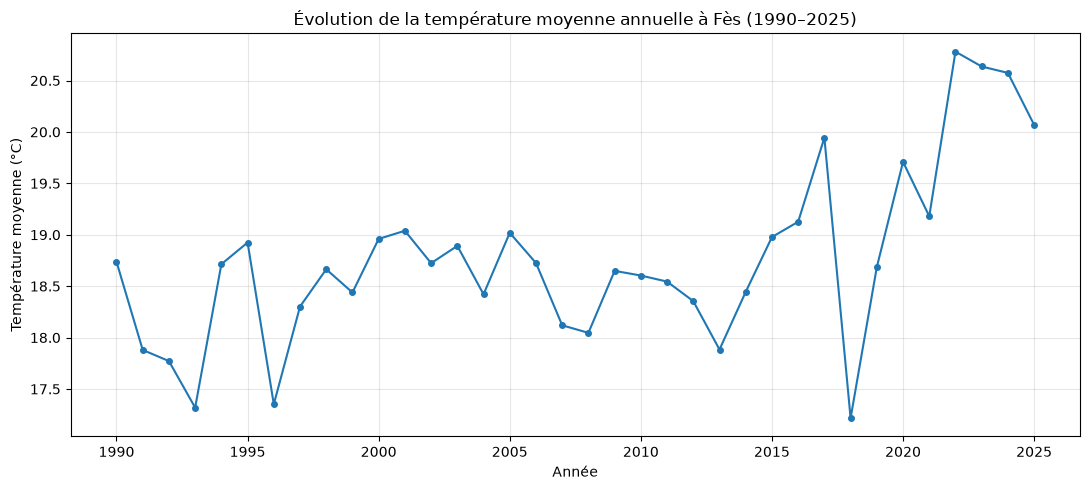

Figure enregistrée : c:\Users\celes\Desktop\PFE\figures\climate_temperature_annual_1990_2025.png


In [8]:
# ÉVOLUTION DE LA TEMPÉRATURE MOYENNE ANNUELLE

fig, ax = plt.subplots(
    figsize=(11, 5)
)

ax.plot(
    annual_climate["Year"],
    annual_climate["Temperature"],
    marker="o",
    linewidth=1.5,
    markersize=4,
)

ax.set_title(
    "Évolution de la température moyenne annuelle à Fès (1990–2025)"
)

ax.set_xlabel("Année")
ax.set_ylabel("Température moyenne (°C)")

ax.grid(
    alpha=0.3
)

fig.tight_layout()


# ENREGISTREMENT

FIG_CLIMATE_TEMPERATURE = (
    FIGURES_DIR
    / "climate_temperature_annual_1990_2025.png"
)

fig.savefig(
    FIG_CLIMATE_TEMPERATURE,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(
    "Figure enregistrée :",
    FIG_CLIMATE_TEMPERATURE
)

#### Température

La température présente la tendance la plus marquée parmi les quatre
variables étudiées. La pente estimée est d'environ **+0,486 °C par décennie**.

Le coefficient \(R^2\) associé à la tendance est d'environ **0,351**. La
tendance linéaire explique donc une partie notable, mais non majoritaire, de
la variabilité interannuelle de la température.

Les données indiquent ainsi une **tendance locale au réchauffement sur la
période étudiée**, malgré des fluctuations importantes d'une année à l'autre.


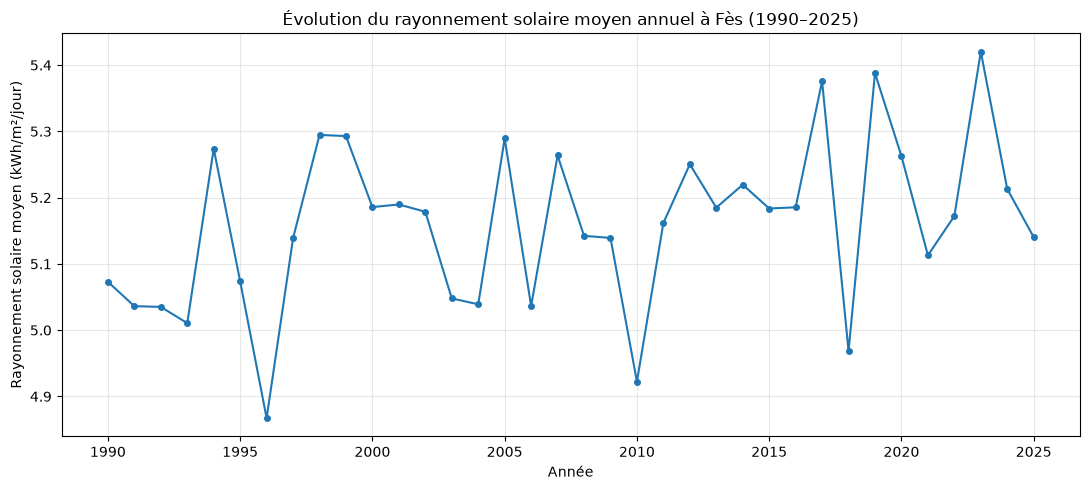

Figure enregistrée : c:\Users\celes\Desktop\PFE\figures\climate_solar_radiation_annual_1990_2025.png


In [9]:
# ÉVOLUTION DU RAYONNEMENT SOLAIRE MOYEN ANNUEL

fig, ax = plt.subplots(
    figsize=(11, 5)
)

ax.plot(
    annual_climate["Year"],
    annual_climate["Solar_radiation"],
    marker="o",
    linewidth=1.5,
    markersize=4,
)

ax.set_title(
    "Évolution du rayonnement solaire moyen annuel à Fès (1990–2025)"
)

ax.set_xlabel("Année")
ax.set_ylabel("Rayonnement solaire moyen (kWh/m²/jour)")

ax.grid(
    alpha=0.3
)

fig.tight_layout()


# ENREGISTREMENT

FIG_CLIMATE_SOLAR = (
    FIGURES_DIR
    / "climate_solar_radiation_annual_1990_2025.png"
)

fig.savefig(
    FIG_CLIMATE_SOLAR,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(
    "Figure enregistrée :",
    FIG_CLIMATE_SOLAR
)

#### Rayonnement solaire

Le rayonnement solaire présente une légère tendance positive, estimée à
environ **+0,045 kWh/m²/jour par décennie**.

Le coefficient \(R^2\), d'environ **0,138**, reste cependant faible. La
tendance temporelle n'explique donc qu'une faible partie des variations
interannuelles observées.

Cette évolution doit par conséquent être interprétée avec davantage de
prudence que celle de la température.



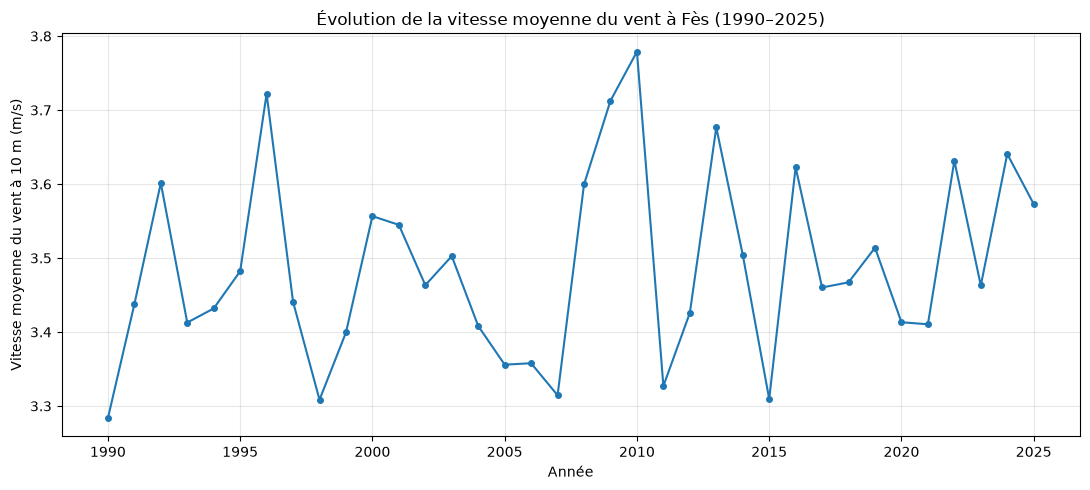

Figure enregistrée : c:\Users\celes\Desktop\PFE\figures\climate_wind_speed_annual_1990_2025.png


In [10]:
# ÉVOLUTION DE LA VITESSE MOYENNE DU VENT

fig, ax = plt.subplots(
    figsize=(11, 5)
)

ax.plot(
    annual_climate["Year"],
    annual_climate["Wind_speed"],
    marker="o",
    linewidth=1.5,
    markersize=4,
)

ax.set_title(
    "Évolution de la vitesse moyenne du vent à Fès (1990–2025)"
)

ax.set_xlabel("Année")
ax.set_ylabel("Vitesse moyenne du vent à 10 m (m/s)")

ax.grid(
    alpha=0.3
)

fig.tight_layout()


# ENREGISTREMENT

FIG_CLIMATE_WIND = (
    FIGURES_DIR
    / "climate_wind_speed_annual_1990_2025.png"
)

fig.savefig(
    FIG_CLIMATE_WIND,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(
    "Figure enregistrée :",
    FIG_CLIMATE_WIND
)

#### Vitesse du vent

La vitesse moyenne du vent présente une pente légèrement positive, d'environ
**+0,025 m/s par décennie**.

Cependant, le coefficient \(R^2\) est très faible (**environ 0,042**).
L'évolution linéaire explique donc très peu la variabilité du vent sur la
période étudiée.

Il serait ainsi excessif de conclure à une augmentation nette de la ressource
éolienne à partir de cette seule tendance.



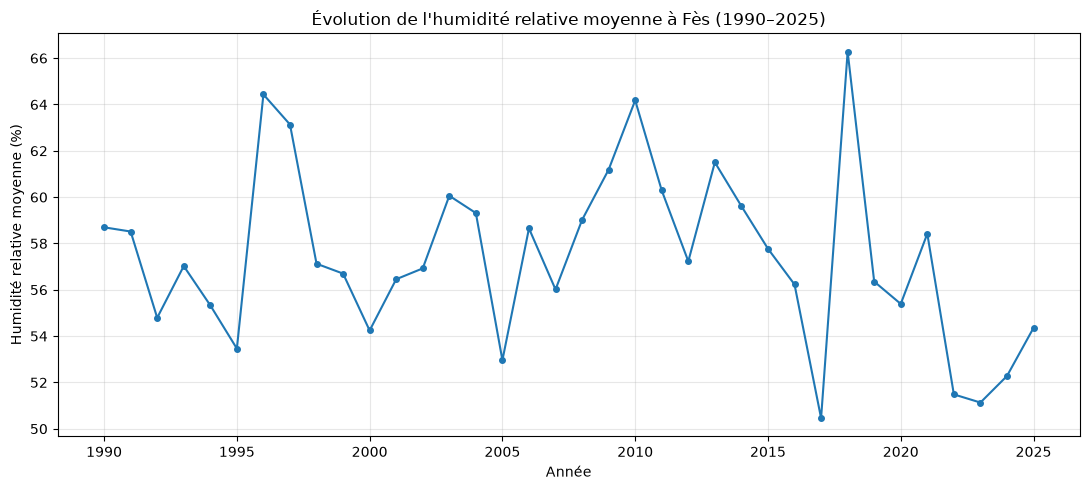

Figure enregistrée : c:\Users\celes\Desktop\PFE\figures\climate_humidity_annual_1990_2025.png


In [11]:
# ÉVOLUTION DE L'HUMIDITÉ RELATIVE MOYENNE

fig, ax = plt.subplots(
    figsize=(11, 5)
)

ax.plot(
    annual_climate["Year"],
    annual_climate["Humidity"],
    marker="o",
    linewidth=1.5,
    markersize=4,
)

ax.set_title(
    "Évolution de l'humidité relative moyenne à Fès (1990–2025)"
)

ax.set_xlabel("Année")
ax.set_ylabel("Humidité relative moyenne (%)")

ax.grid(
    alpha=0.3
)

fig.tight_layout()


# ENREGISTREMENT

FIG_CLIMATE_HUMIDITY = (
    FIGURES_DIR
    / "climate_humidity_annual_1990_2025.png"
)

fig.savefig(
    FIG_CLIMATE_HUMIDITY,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(
    "Figure enregistrée :",
    FIG_CLIMATE_HUMIDITY
)

#### Humidité relative

L'humidité relative présente une pente négative d'environ **−0,724 point de
pourcentage par décennie**.

Là encore, le coefficient \(R^2\) est faible (**environ 0,041**), ce qui
indique une forte variabilité interannuelle par rapport à la tendance
linéaire estimée.

La série suggère donc une diminution moyenne sur la période, mais cette
évolution doit être considérée avec prudence.

### Bilan

L'analyse des données NASA POWER montre que les différentes variables
climatiques n'évoluent pas avec la même intensité sur la période 1990–2025.

La température constitue le signal de long terme le plus marqué parmi les
variables étudiées, avec une augmentation estimée à environ **0,49 °C par
décennie**.

Le rayonnement solaire présente également une légère évolution positive,
tandis que les tendances de la vitesse du vent et de l'humidité relative sont
beaucoup moins clairement structurées en raison de leur forte variabilité
interannuelle.

Ces résultats montrent l'intérêt de ne pas considérer les ressources
énergétiques renouvelables comme totalement stationnaires dans le temps.
L'évolution des conditions climatiques peut modifier progressivement les
conditions dans lesquelles la production et la demande énergétiques doivent
être anticipées.

Cependant, cette analyse reste une **analyse locale de tendances observées**.
Elle ne permet pas, à elle seule, d'attribuer ces évolutions au changement
climatique anthropique. Une telle attribution nécessiterait notamment des
analyses climatiques complémentaires et la prise en compte de modèles ou de
scénarios climatiques dédiés.

Dans le cadre de ce PFE, cette analyse apporte donc la dimension de long terme
qui complète la prévision énergétique à court terme développée dans les
notebooks précédents.

## 8. Estimation des tendances climatiques de long terme

La visualisation permet d'identifier la variabilité interannuelle, mais elle
ne suffit pas à quantifier une éventuelle évolution sur la période étudiée.

Une régression linéaire simple est donc ajustée séparément pour chaque
variable climatique :

[
y_t = a times t + b
]

où :

- \(t\) représente l'année ;
- \(y_t\) représente la valeur annuelle de la variable étudiée ;
- \(a\) représente la pente temporelle estimée.

Pour faciliter l'interprétation, la pente est également exprimée **par
décennie**.

Une pente positive traduit une augmentation moyenne sur la période étudiée,
tandis qu'une pente négative traduit une diminution moyenne.

Le coefficient \(R^2\) est également calculé afin d'indiquer quelle part de la
variabilité interannuelle est expliquée par cette tendance linéaire.

Il est important de souligner qu'une tendance statistique observée sur la
période 1990–2025 ne constitue pas, à elle seule, une preuve d'attribution au
changement climatique anthropique. Elle permet uniquement de caractériser
l'évolution locale observée dans les données disponibles.

In [12]:
# FONCTION D'ESTIMATION D'UNE TENDANCE LINÉAIRE

def estimate_climate_trend(
    dataframe,
    target,
    unit,
):

    X = dataframe[["Year"]]
    y = dataframe[target]

    model = LinearRegression()

    model.fit(
        X,
        y
    )

    predictions = model.predict(X)

    slope_year = float(
        model.coef_[0]
    )

    slope_decade = (
        slope_year * 10
    )

    r2 = r2_score(
        y,
        predictions
    )

    return {
        "Variable": target,
        "Unit": unit,
        "Slope_per_year": slope_year,
        "Slope_per_decade": slope_decade,
        "R2_trend": r2,
        "Predictions": predictions,
    }

In [13]:
# CALCUL DES TENDANCES

trend_temperature = estimate_climate_trend(
    annual_climate,
    "Temperature",
    "°C",
)

trend_solar = estimate_climate_trend(
    annual_climate,
    "Solar_radiation",
    "kWh/m²/jour",
)

trend_wind = estimate_climate_trend(
    annual_climate,
    "Wind_speed",
    "m/s",
)

trend_humidity = estimate_climate_trend(
    annual_climate,
    "Humidity",
    "%",
)


trend_results = pd.DataFrame(
    [
        {
            key: value
            for key, value in trend.items()
            if key != "Predictions"
        }
        for trend in [
            trend_temperature,
            trend_solar,
            trend_wind,
            trend_humidity,
        ]
    ]
)


print("TENDANCES CLIMATIQUES 1990–2025")

display(
    trend_results.round(6)
)

TENDANCES CLIMATIQUES 1990–2025


,Variable,Unit,Slope_per_year,Slope_per_decade,R2_trend
0,Temperature,°C,0.048614,0.486140,0.350775
1,Solar_radiation,kWh/m²/jour,0.004475,0.044747,0.137718
2,Wind_speed,m/s,0.002491,0.024909,0.042202
3,Humidity,%,-0.072365,-0.723648,0.041097


In [14]:
# CALCUL DES TENDANCES

trend_temperature = estimate_climate_trend(
    annual_climate,
    "Temperature",
    "°C",
)

trend_solar = estimate_climate_trend(
    annual_climate,
    "Solar_radiation",
    "kWh/m²/jour",
)

trend_wind = estimate_climate_trend(
    annual_climate,
    "Wind_speed",
    "m/s",
)

trend_humidity = estimate_climate_trend(
    annual_climate,
    "Humidity",
    "%",
)


trend_results = pd.DataFrame(
    [
        {
            key: value
            for key, value in trend.items()
            if key != "Predictions"
        }
        for trend in [
            trend_temperature,
            trend_solar,
            trend_wind,
            trend_humidity,
        ]
    ]
)


print("TENDANCES CLIMATIQUES 1990–2025")

display(
    trend_results.round(6)
)

TENDANCES CLIMATIQUES 1990–2025


,Variable,Unit,Slope_per_year,Slope_per_decade,R2_trend
0,Temperature,°C,0.048614,0.486140,0.350775
1,Solar_radiation,kWh/m²/jour,0.004475,0.044747,0.137718
2,Wind_speed,m/s,0.002491,0.024909,0.042202
3,Humidity,%,-0.072365,-0.723648,0.041097


In [15]:
# FONCTION DE VISUALISATION D'UNE TENDANCE

def plot_climate_trend(
    dataframe,
    target,
    predictions,
    ylabel,
    title,
    output_path,
):

    fig, ax = plt.subplots(
        figsize=(11, 5)
    )

    ax.plot(
        dataframe["Year"],
        dataframe[target],
        marker="o",
        linewidth=1.3,
        markersize=4,
        label="Moyenne annuelle",
    )

    ax.plot(
        dataframe["Year"],
        predictions,
        linestyle="--",
        linewidth=2,
        label="Tendance linéaire",
    )

    ax.set_title(title)

    ax.set_xlabel("Année")
    ax.set_ylabel(ylabel)

    ax.grid(
        alpha=0.3
    )

    ax.legend()

    fig.tight_layout()

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

    print(
        "Figure enregistrée :",
        output_path
    )

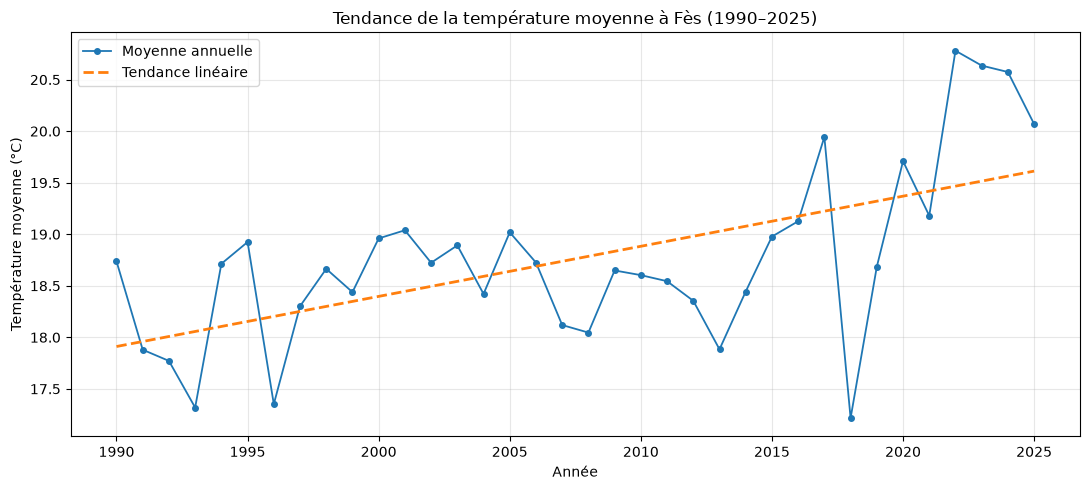

Figure enregistrée : c:\Users\celes\Desktop\PFE\figures\climate_temperature_trend_1990_2025.png


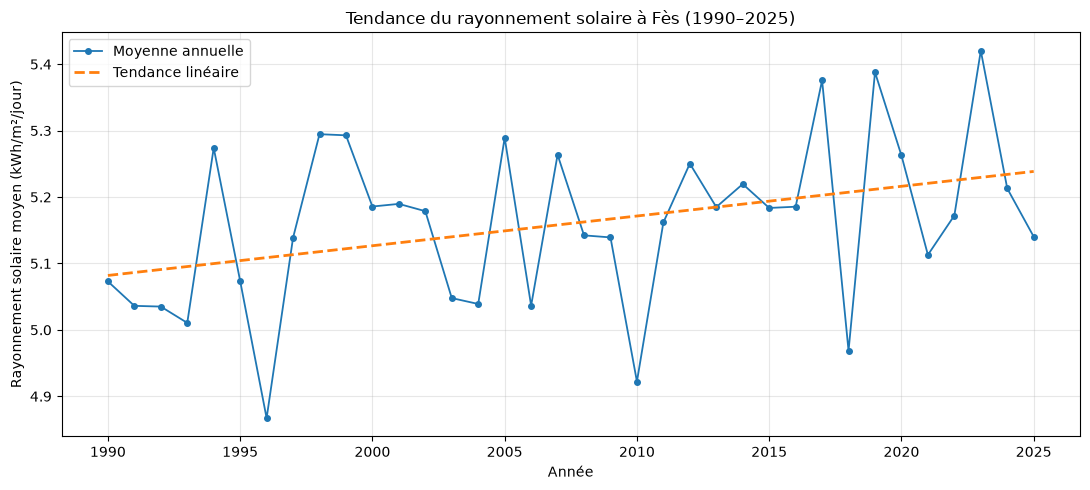

Figure enregistrée : c:\Users\celes\Desktop\PFE\figures\climate_solar_radiation_trend_1990_2025.png


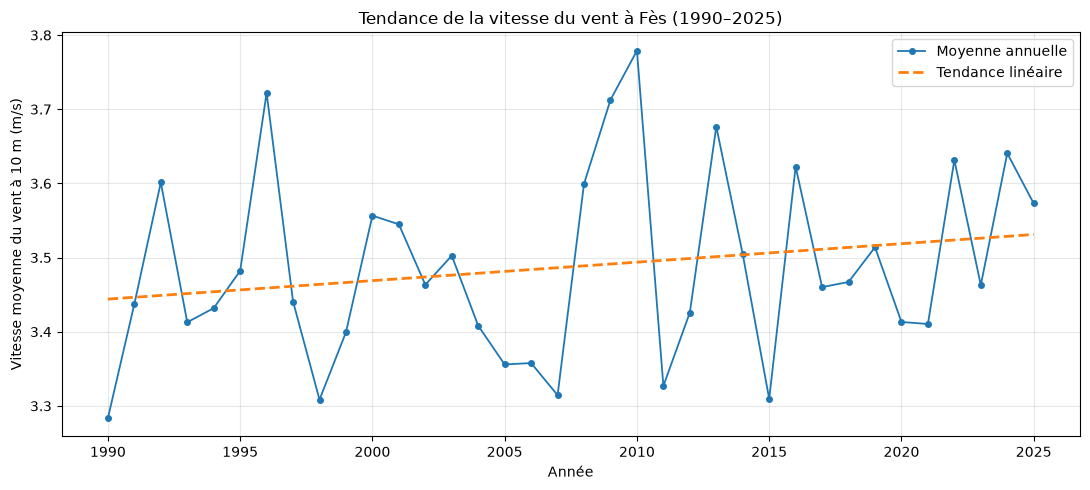

Figure enregistrée : c:\Users\celes\Desktop\PFE\figures\climate_wind_speed_trend_1990_2025.png


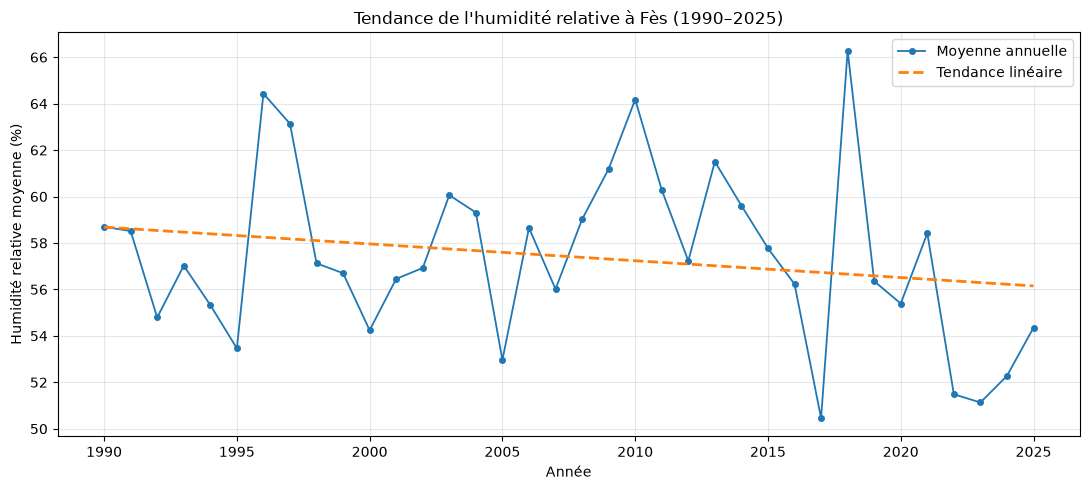

Figure enregistrée : c:\Users\celes\Desktop\PFE\figures\climate_humidity_trend_1990_2025.png


In [16]:
# FIGURES DES TENDANCES CLIMATIQUES

plot_climate_trend(
    annual_climate,
    "Temperature",
    trend_temperature["Predictions"],
    "Température moyenne (°C)",
    "Tendance de la température moyenne à Fès (1990–2025)",
    FIGURES_DIR / "climate_temperature_trend_1990_2025.png",
)


plot_climate_trend(
    annual_climate,
    "Solar_radiation",
    trend_solar["Predictions"],
    "Rayonnement solaire moyen (kWh/m²/jour)",
    "Tendance du rayonnement solaire à Fès (1990–2025)",
    FIGURES_DIR / "climate_solar_radiation_trend_1990_2025.png",
)


plot_climate_trend(
    annual_climate,
    "Wind_speed",
    trend_wind["Predictions"],
    "Vitesse moyenne du vent à 10 m (m/s)",
    "Tendance de la vitesse du vent à Fès (1990–2025)",
    FIGURES_DIR / "climate_wind_speed_trend_1990_2025.png",
)


plot_climate_trend(
    annual_climate,
    "Humidity",
    trend_humidity["Predictions"],
    "Humidité relative moyenne (%)",
    "Tendance de l'humidité relative à Fès (1990–2025)",
    FIGURES_DIR / "climate_humidity_trend_1990_2025.png",
)

## 9. Significativité statistique des tendances

La pente d'une régression linéaire indique la direction et l'amplitude d'une
évolution temporelle, mais elle ne permet pas à elle seule de déterminer si
cette évolution est suffisamment marquée par rapport à la variabilité des
observations.

Afin de compléter l'analyse, la significativité statistique des tendances est
évaluée à l'aide d'une régression linéaire fournissant :

- la pente annuelle ;
- la pente par décennie ;
- la valeur de \(p\) associée à la pente ;
- l'intervalle de confiance à 95 %.

Dans cette étude, une valeur de \(p < 0,05\) est utilisée comme seuil
conventionnel pour considérer qu'une tendance linéaire est statistiquement
significative.

Cette analyse ne constitue toutefois pas une attribution causale au changement
climatique. Elle permet uniquement d'évaluer la robustesse statistique des
évolutions observées localement sur la période 1990–2025.

In [17]:
# SIGNIFICATIVITÉ STATISTIQUE DES TENDANCES

from scipy.stats import linregress


trend_significance_rows = []

variables_info = {
    "Temperature": "°C",
    "Solar_radiation": "kWh/m²/jour",
    "Wind_speed": "m/s",
    "Humidity": "%",
}


for variable, unit in variables_info.items():

    result = linregress(
        annual_climate["Year"],
        annual_climate[variable],
    )

    # Intervalle de confiance à 95 %
    ci_lower = (
        result.slope
        - 1.96 * result.stderr
    )

    ci_upper = (
        result.slope
        + 1.96 * result.stderr
    )

    trend_significance_rows.append(
        {
            "Variable": variable,
            "Unité": unit,
            "Pente_par_an": result.slope,
            "Pente_par_décennie": result.slope * 10,
            "IC95_inf_décennie": ci_lower * 10,
            "IC95_sup_décennie": ci_upper * 10,
            "p_value": result.pvalue,
            "R2": result.rvalue ** 2,
            "Significative_5%": result.pvalue < 0.05,
        }
    )


trend_significance = pd.DataFrame(
    trend_significance_rows
)


print("SIGNIFICATIVITÉ DES TENDANCES CLIMATIQUES")

display(
    trend_significance.round(6)
)

SIGNIFICATIVITÉ DES TENDANCES CLIMATIQUES


,Variable,Unité,Pente_par_an,Pente_par_décennie,IC95_inf_décennie,IC95_sup_décennie,p_value,R2,Significative_5%
0,Temperature,°C,0.048614,0.486140,0.263829,0.708451,0.000142,0.350775,True
1,Solar_radiation,kWh/m²/jour,0.004475,0.044747,0.007110,0.082383,0.025861,0.137718,True
2,Wind_speed,m/s,0.002491,0.024909,-0.014979,0.064797,0.229380,0.042202,False
3,Humidity,%,-0.072365,-0.723648,-1.898620,0.451324,0.235711,0.041097,False


### Interprétation 

L'analyse statistique confirme que toutes les évolutions observées ne présentent
pas le même niveau de robustesse.

#### Température

La température présente une augmentation estimée à **+0,486 °C par décennie**.
Cette tendance est statistiquement significative (\(p = 0,000142\)) et son
intervalle de confiance à 95 % est entièrement positif, compris entre environ
**+0,264 et +0,708 °C par décennie**.

Le coefficient \(R^2\) atteint environ **0,351**, ce qui indique que la tendance
temporelle linéaire explique une part notable, mais non majoritaire, de la
variabilité interannuelle.

Parmi les variables étudiées, la température fournit ainsi le signal de long
terme le plus net sur la période 1990–2025.

#### Rayonnement solaire

Le rayonnement solaire présente une augmentation estimée à environ
**+0,045 kWh/m²/jour par décennie**.

Cette tendance est également statistiquement significative au seuil de 5 %
(\(p = 0,0259\)). Son intervalle de confiance à 95 % reste positif, entre
environ **+0,007 et +0,082 kWh/m²/jour par décennie**.

Toutefois, le coefficient \(R^2\) est plus faible, environ **0,138**. La
tendance existe donc dans les données étudiées, mais la variabilité
interannuelle demeure importante.

#### Vitesse du vent

La vitesse du vent présente une faible pente positive d'environ
**+0,025 m/s par décennie**.

Cette tendance n'est cependant pas statistiquement significative
(\(p = 0,229\)). De plus, l'intervalle de confiance à 95 % contient zéro.

Les données disponibles ne permettent donc pas de conclure à une évolution
linéaire significative de la vitesse moyenne du vent sur la période étudiée.

#### Humidité relative

L'humidité relative présente une pente négative estimée à environ
**−0,724 point de pourcentage par décennie**.

Cette tendance n'est pas statistiquement significative au seuil de 5 %
(\(p = 0,236\)) et son intervalle de confiance contient également zéro.

La diminution estimée doit donc être considérée comme une évolution observée
dans l'échantillon, mais elle ne constitue pas une tendance linéaire
statistiquement établie.

### Bilan

Sur les quatre variables étudiées, seules **la température et le rayonnement
solaire présentent une tendance linéaire statistiquement significative** sur
la période 1990–2025.

Ces résultats caractérisent des évolutions climatiques locales observées à Fès.
Ils ne permettent cependant pas, à eux seuls, d'attribuer causalement ces
évolutions au changement climatique anthropique.

In [18]:
# ENREGISTREMENT DES TENDANCES CLIMATIQUES

CLIMATE_TRENDS_FILE = (
    RESULTS_DIR
    / "climate_trends_fes_1990_2025.csv"
)

trend_significance.to_csv(
    CLIMATE_TRENDS_FILE,
    index=False,
)


print(
    "Résultats enregistrés :",
    CLIMATE_TRENDS_FILE
)

Résultats enregistrés : c:\Users\celes\Desktop\PFE\results\climate_trends_fes_1990_2025.csv


## 10. Analyse des anomalies climatiques

L'étude des moyennes annuelles permet d'observer l'évolution générale des
variables, mais les anomalies facilitent l'identification des années
particulièrement éloignées d'une situation de référence.

Une anomalie climatique correspond ici à la différence entre la valeur
observée pour une année et la moyenne calculée sur une période de référence.

La période **1991-2020** est utilisée comme référence climatologique. Pour
chaque variable :

\[
Anomalie_t = Valeur_t - Moyenne_{1991-2020}
\]

Une anomalie positive indique une valeur supérieure à la moyenne de référence,
tandis qu'une anomalie négative indique une valeur inférieure.

Cette représentation permet notamment d'examiner si les années récentes se
situent plus fréquemment au-dessus ou au-dessous des conditions moyennes de
référence.

In [19]:
# PÉRIODE CLIMATOLOGIQUE DE RÉFÉRENCE : 1991-2020

reference_period = annual_climate[
    annual_climate["Year"].between(
        1991,
        2020
    )
]


climate_reference = (
    reference_period[
        [
            "Temperature",
            "Solar_radiation",
            "Wind_speed",
            "Humidity",
        ]
    ]
    .mean()
)


print("RÉFÉRENCE CLIMATOLOGIQUE 1991-2020")

display(
    climate_reference
    .to_frame("Moyenne_1991_2020")
    .round(4)
)

RÉFÉRENCE CLIMATOLOGIQUE 1991-2020


,Moyenne_1991_2020
Temperature,18.5150
Solar_radiation,5.1546
Wind_speed,3.4850
Humidity,58.0209


In [20]:
# CALCUL DES ANOMALIES ANNUELLES

climate_anomalies = (
    annual_climate.copy()
)


for variable in [
    "Temperature",
    "Solar_radiation",
    "Wind_speed",
    "Humidity",
]:

    climate_anomalies[
        f"{variable}_anomaly"
    ] = (
        climate_anomalies[variable]
        - climate_reference[variable]
    )


print("ANOMALIES CLIMATIQUES")

display(
    climate_anomalies.head()
)

ANOMALIES CLIMATIQUES


,Year,Solar_radiation,Temperature,Humidity,Wind_speed,Temperature_anomaly,Solar_radiation_anomaly,Wind_speed_anomaly,Humidity_anomaly
0,1990,5.072964,18.737616,58.696986,3.283534,0.222641,-0.081607,-0.201496,0.676065
1,1991,5.036196,17.879890,58.514932,3.437452,-0.635085,-0.118375,-0.047578,0.494011
2,1992,5.035089,17.771612,54.791612,3.601311,-0.743363,-0.119482,0.116281,-3.229309
3,1993,5.010558,17.318904,57.023945,3.412767,-1.196071,-0.144013,-0.072263,-0.996976
4,1994,5.273957,18.713699,55.328493,3.431836,0.198723,0.119386,-0.053195,-2.692428


## 11. Anomalies de température

Les anomalies de température permettent de représenter chaque année par
rapport à la température moyenne de la période climatologique 1991-2020.

Cette représentation complète l'analyse de tendance : elle permet de vérifier
visuellement la répartition des années relativement froides et relativement
chaudes par rapport à la référence.

L'objectif n'est donc plus seulement de mesurer une pente moyenne, mais
d'observer comment les écarts à la climatologie de référence se répartissent
dans le temps.

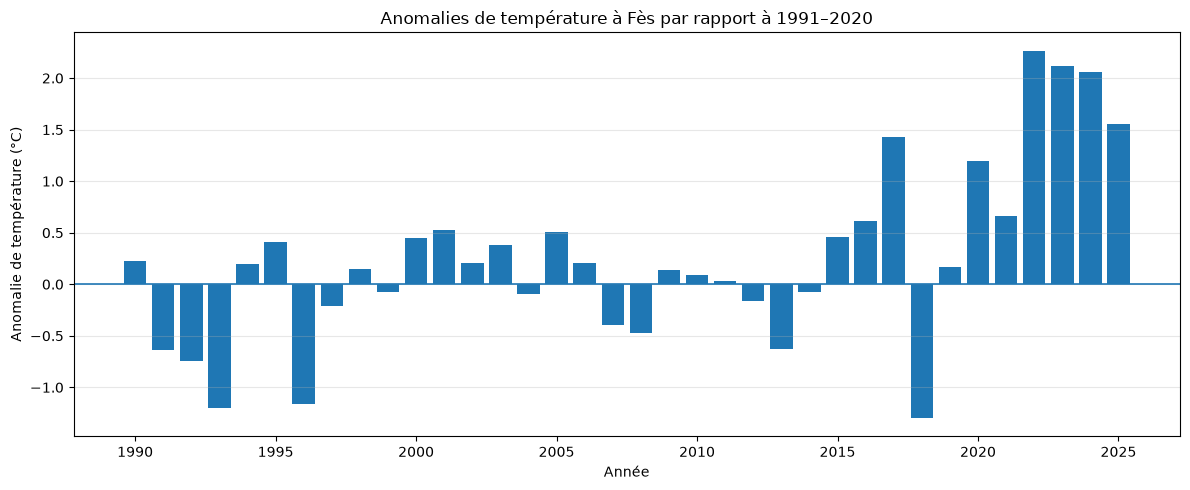

Figure enregistrée : c:\Users\celes\Desktop\PFE\figures\climate_temperature_anomalies_1990_2025.png


In [21]:
# ANOMALIES DE TEMPÉRATURE

fig, ax = plt.subplots(
    figsize=(12, 5)
)

ax.bar(
    climate_anomalies["Year"],
    climate_anomalies["Temperature_anomaly"],
)

ax.axhline(
    0,
    linewidth=1.2,
)

ax.set_title(
    "Anomalies de température à Fès par rapport à 1991–2020"
)

ax.set_xlabel("Année")
ax.set_ylabel("Anomalie de température (°C)")

ax.grid(
    axis="y",
    alpha=0.3,
)

fig.tight_layout()


# ENREGISTREMENT

FIG_TEMPERATURE_ANOMALY = (
    FIGURES_DIR
    / "climate_temperature_anomalies_1990_2025.png"
)

fig.savefig(
    FIG_TEMPERATURE_ANOMALY,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


print(
    "Figure enregistrée :",
    FIG_TEMPERATURE_ANOMALY
)

### Interprétation des anomalies

La représentation des anomalies confirme l'existence d'une variabilité
interannuelle importante de la température à Fès.

Les premières décennies comportent plusieurs années dont la température
moyenne est inférieure à la référence climatologique 1991–2020, tandis que les
années les plus récentes présentent plus fréquemment des anomalies positives.

Cette évolution visuelle est cohérente avec le résultat obtenu précédemment par
régression linéaire, qui met en évidence une augmentation statistiquement
significative de la température sur la période 1990–2025.

L'analyse des anomalies apporte ainsi une lecture complémentaire : la tendance
de long terme ne signifie pas que chaque année est systématiquement plus chaude
que la précédente. Des fluctuations interannuelles persistent autour de
l'évolution générale.

Cette distinction entre variabilité annuelle et tendance de long terme est
essentielle dans l'interprétation des changements climatiques observés.

## 12. Comparaison entre le début et la fin de la période

Afin de compléter l'analyse des tendances, les conditions climatiques du début
et de la fin de la période sont comparées.

Deux fenêtres de dix années sont considérées :

- **1990-1999** : début de la période ;
- **2016-2025** : fin de la période.

Pour chaque variable, la moyenne de ces deux périodes est calculée ainsi que
leur différence.

Cette approche fournit une lecture complémentaire à la régression linéaire :
elle permet d'exprimer les changements observés dans les unités physiques des
variables étudiées.

Elle ne remplace toutefois pas l'analyse de tendance, car le résultat peut
dépendre des fenêtres temporelles choisies.

In [22]:
# COMPARAISON DÉBUT / FIN DE PÉRIODE

early_period = annual_climate[
    annual_climate["Year"].between(
        1990,
        1999
    )
]

recent_period = annual_climate[
    annual_climate["Year"].between(
        2016,
        2025
    )
]


comparison_rows = []

for variable, unit in variables_info.items():

    early_mean = (
        early_period[variable].mean()
    )

    recent_mean = (
        recent_period[variable].mean()
    )

    difference = (
        recent_mean
        - early_mean
    )

    relative_change = (
        difference
        / early_mean
        * 100
    )

    comparison_rows.append(
        {
            "Variable": variable,
            "Unité": unit,
            "Moyenne_1990_1999": early_mean,
            "Moyenne_2016_2025": recent_mean,
            "Différence": difference,
            "Variation_%": relative_change,
        }
    )


period_comparison = pd.DataFrame(
    comparison_rows
)


print("COMPARAISON CLIMATIQUE : 1990-1999 VS 2016-2025")

display(
    period_comparison.round(4)
)

COMPARAISON CLIMATIQUE : 1990-1999 VS 2016-2025


,Variable,Unité,Moyenne_1990_1999,Moyenne_2016_2025,Différence,Variation_%
0,Temperature,°C,18.2103,19.5921,1.3818,7.5880
1,Solar_radiation,kWh/m²/jour,5.1096,5.2239,0.1143,2.2371
2,Wind_speed,m/s,3.4519,3.5195,0.0676,1.9582
3,Humidity,%,57.9210,55.2382,-2.6828,-4.6319


### Interprétation 

La comparaison entre les décennies 1990-1999 et 2016-2025 permet de compléter
l'analyse des tendances par une lecture directement exprimée dans les unités
physiques des variables.

La différence la plus marquée concerne la **température moyenne**, qui passe
d'environ **18,21 °C** sur la période 1990-1999 à **19,59 °C** sur la période
2016-2025, soit une différence d'environ **+1,38 °C**.

Le **rayonnement solaire moyen** augmente également, passant d'environ
**5,11 à 5,22 kWh/m²/jour**, soit une différence d'environ
**+0,11 kWh/m²/jour**.

La **vitesse moyenne du vent** présente une variation beaucoup plus faible,
d'environ **+0,068 m/s** entre les deux périodes. Cette différence doit être
interprétée avec prudence puisque l'analyse statistique précédente n'a pas
identifié de tendance linéaire significative pour cette variable.

Enfin, l'**humidité relative moyenne** diminue d'environ **2,68 points de
pourcentage** entre les deux périodes. Là encore, la tendance linéaire associée
n'étant pas statistiquement significative, cette différence entre fenêtres ne
suffit pas à établir une évolution générale robuste.

Ces résultats montrent donc principalement un **réchauffement local marqué**
entre le début et la fin de la période étudiée, accompagné d'une évolution
plus modérée du rayonnement solaire. Les changements observés pour le vent et
l'humidité sont moins robustes statistiquement.

La comparaison entre deux périodes reste toutefois descriptive et dépend du
choix des fenêtres temporelles. Elle doit donc être interprétée conjointement
avec les tendances, les intervalles de confiance et les tests de
significativité.

In [23]:
# ENREGISTREMENT DE LA COMPARAISON

CLIMATE_COMPARISON_FILE = (
    RESULTS_DIR
    / "climate_period_comparison_fes.csv"
)

period_comparison.to_csv(
    CLIMATE_COMPARISON_FILE,
    index=False,
)


print(
    "Résultats enregistrés :",
    CLIMATE_COMPARISON_FILE
)

Résultats enregistrés : c:\Users\celes\Desktop\PFE\results\climate_period_comparison_fes.csv


# Partie II - Analyse énergétique et prévisionnelle


## 13. Articulation entre climat, prévision et gestion énergétique

L'analyse précédente a mis en évidence l'existence d'évolutions climatiques
locales sur la période 1990-2025, avec notamment une augmentation
statistiquement significative de la température moyenne et une évolution plus
modérée du rayonnement solaire.

À plus court terme, les conditions météorologiques influencent directement
plusieurs composantes du système énergétique :

- le rayonnement solaire conditionne la ressource photovoltaïque ;
- la vitesse du vent influence la ressource éolienne ;
- la température et les conditions météorologiques peuvent modifier la demande
  électrique.

Les notebooks précédents ont exploité ces informations, ainsi que les
caractéristiques temporelles et l'historique énergétique, afin de prévoir à
l'horizon H+1 :

- la production photovoltaïque ;
- la production éolienne ;
- la demande électrique.

Une prévision précise ne constitue cependant pas une décision énergétique à
elle seule.

L'objectif de cette seconde partie est donc de transformer les trois prévisions
en un indicateur synthétique permettant d'anticiper l'état du système pour
l'heure suivante.

Le bilan énergétique prévisionnel est défini par :

[
B_{t+1}^{prévu}=hat{P}_{PV,t+1}+hat{P}_{Wind,t+1}-hat{D}_{t+1}
]

où :

- \(hat{P}_{PV,t+1}) représente la production photovoltaïque prévue ;
- \(hat{P}_{Wind,t+1}) représente la production éolienne prévue ;
- \(hat{D}_{t+1}) représente la demande électrique prévue.

Un bilan positif indique un surplus renouvelable prévisionnel, tandis qu'un
bilan négatif indique un déficit prévisionnel par rapport à la demande.

Cette approche ne constitue pas une optimisation complète du système
électrique. Elle représente un **prototype d'aide à la décision**, dans lequel
les prévisions issues de l'IA sont transformées en information opérationnelle.

## 14. Réutilisation des prédictions du pipeline principal

Afin de conserver une séparation claire entre modélisation et aide à la
décision, aucun nouveau modèle de prévision n'est entraîné dans cette partie.

Les prédictions obtenues précédemment sur le jeu de test final sont réutilisées.

Le fichier contient, pour chaque timestamp :

- la production photovoltaïque réelle et prédite ;
- la production éolienne réelle et prédite ;
- la demande électrique réelle et prédite.

Cette organisation permet de construire deux bilans :

1. un **bilan prévisionnel**, disponible avant l'observation de l'heure cible ;
2. un **bilan réel**, utilisé a posteriori pour évaluer la qualité de
   l'anticipation.

Le jeu de test reste ainsi un jeu d'évaluation : aucune information future
n'est utilisée pour modifier les modèles de prévision.

In [24]:
# CHARGEMENT DES PRÉDICTIONS ÉNERGÉTIQUES

PREDICTIONS_FILE = (
    RESULTS_DIR
    / "powerbi_predictions.csv"
)


print("PRÉDICTIONS ÉNERGÉTIQUES H+1")

print(
    "Fichier :",
    PREDICTIONS_FILE
)

print(
    "Disponible :",
    PREDICTIONS_FILE.exists()
)


energy_predictions = pd.read_csv(
    PREDICTIONS_FILE
)


print(
    "\nDimensions :",
    energy_predictions.shape
)

print("\nColonnes :")

for column in energy_predictions.columns:
    print("-", column)


print("\nPremières observations :")

display(
    energy_predictions.head()
)

PRÉDICTIONS ÉNERGÉTIQUES H+1
Fichier : c:\Users\celes\Desktop\PFE\results\powerbi_predictions.csv
Disponible : True

Dimensions : (47043, 21)

Colonnes :
- Time
- PV_reel
- PV_predit
- PV_erreur
- PV_naif
- PV_erreur_naif
- Wind_reel
- Wind_predit
- Wind_erreur
- Wind_naif
- Wind_erreur_naif
- Demand_reel
- Demand_predit
- Demand_erreur
- Demand_naif
- Demand_erreur_naif
- Year
- Month
- Day
- Hour
- Weekday

Premières observations :


,Time,PV_reel,PV_predit,PV_erreur,PV_naif,PV_erreur_naif,Wind_reel,Wind_predit,Wind_erreur,Wind_naif,...,Demand_reel,Demand_predit,Demand_erreur,Demand_naif,Demand_erreur_naif,Year,Month,Day,Hour,Weekday
0,2021-07-21 14:45:00,10535.0,10562.036047,-27.036047,9911.0,624.0,1975.0,2236.895625,-261.895625,2573.0,...,39163.0,39220.328773,-57.328773,39085.0,78.0,2021,7,21,14,Wednesday
1,2021-07-21 14:50:00,10477.0,10590.855371,-113.855371,10443.0,34.0,2029.0,2195.640560,-166.640560,2638.0,...,39299.0,39305.369737,-6.369737,39242.0,57.0,2021,7,21,14,Wednesday
2,2021-07-21 14:55:00,10413.0,10611.317361,-198.317361,10364.0,49.0,2044.0,2139.664116,-95.664116,2684.0,...,39410.0,39257.723299,152.276701,39415.0,-5.0,2021,7,21,14,Wednesday
3,2021-07-21 15:00:00,10227.0,10278.300883,-51.300883,10153.0,74.0,2082.0,2157.538280,-75.538280,2710.0,...,39506.0,39216.441119,289.558881,39510.0,-4.0,2021,7,21,15,Wednesday
4,2021-07-21 15:05:00,10059.0,10183.434948,-124.434948,9662.0,397.0,2105.0,2055.432264,49.567736,2718.0,...,39431.0,39749.364475,-318.364475,39443.0,-12.0,2021,7,21,15,Wednesday


### Interprétation 

Le fichier contient **47 043 observations** issues du jeu de test final.

Pour chacune des trois grandeurs énergétiques - production photovoltaïque,
production éolienne et demande électrique - les valeurs réelles, les
prédictions du modèle et les valeurs de la baseline naïve sont disponibles.

Les six variables nécessaires à la construction du bilan énergétique sont
présentes et ne comportent aucune valeur manquante.

La seconde partie de l'étude peut donc réutiliser directement les prédictions
produites par le pipeline de Machine Learning, sans entraîner de nouveau
modèle.

## 15. Contrôle des données énergétiques

Avant de construire le bilan production-demande, les colonnes nécessaires sont
contrôlées.

Cette étape permet de vérifier :

- la présence des productions photovoltaïque et éolienne ;
- la présence de la demande ;
- la disponibilité des valeurs réelles et prédites ;
- l'absence de valeurs manquantes susceptibles de fausser le bilan.

Le bilan énergétique n'est calculé qu'après validation de ces éléments.

In [25]:
# COLONNES NÉCESSAIRES

required_energy_columns = [
    "PV_reel",
    "PV_predit",
    "Wind_reel",
    "Wind_predit",
    "Demand_reel",
    "Demand_predit",
]


missing_columns = [
    column
    for column in required_energy_columns
    if column not in energy_predictions.columns
]


print("CONTRÔLE DES COLONNES")

if len(missing_columns) == 0:
    print("OK, toutes les colonnes nécessaires sont disponibles.")
else:
    print(
        "Colonnes manquantes :",
        missing_columns
    )


print("\nValeurs manquantes :")

display(
    energy_predictions[
        required_energy_columns
    ]
    .isna()
    .sum()
    .to_frame("Nombre")
)

CONTRÔLE DES COLONNES
OK, toutes les colonnes nécessaires sont disponibles.

Valeurs manquantes :


,Nombre
PV_reel,0
PV_predit,0
Wind_reel,0
Wind_predit,0
Demand_reel,0
Demand_predit,0


## 16. Construction du bilan production–demande

Le bilan énergétique permet de réunir les trois problèmes de prévision
développés précédemment dans un indicateur unique.

Pour chaque observation du jeu de test, deux bilans sont calculés.

### Bilan réel

[B^{réel}=P_{PV}^{réel}+P_{Wind}^{réel}-D^{réelle}]

### Bilan prévisionnel

[B^{prévu}=P_{PV}^{prévu}+P_{Wind}^{prévu}-D^{prévue}]

L'interprétation est la suivante :

- (B > 0) : la production renouvelable est supérieure à la demande ;
- (B < 0) : la production renouvelable est insuffisante pour couvrir la
  demande ;
- (B approx 0) : production et demande sont proches de l'équilibre.

Le bilan réel n'intervient pas dans la décision anticipée. Il est uniquement
utilisé après observation afin d'évaluer la qualité du bilan prévisionnel.

In [26]:
# CONSTRUCTION DES BILANS ÉNERGÉTIQUES

energy_balance = (
    energy_predictions.copy()
)


energy_balance["Renewable_real"] = (
    energy_balance["PV_reel"]
    + energy_balance["Wind_reel"]
)

energy_balance["Renewable_pred"] = (
    energy_balance["PV_predit"]
    + energy_balance["Wind_predit"]
)


energy_balance["Balance_real"] = (
    energy_balance["Renewable_real"]
    - energy_balance["Demand_reel"]
)

energy_balance["Balance_pred"] = (
    energy_balance["Renewable_pred"]
    - energy_balance["Demand_predit"]
)


energy_balance["Balance_error"] = (
    energy_balance["Balance_real"]
    - energy_balance["Balance_pred"]
)


print("BILAN ÉNERGÉTIQUE")

display(
    energy_balance[
        [
            "Renewable_real",
            "Renewable_pred",
            "Demand_reel",
            "Demand_predit",
            "Balance_real",
            "Balance_pred",
            "Balance_error",
        ]
    ]
    .head(10)
)

BILAN ÉNERGÉTIQUE


,Renewable_real,Renewable_pred,Demand_reel,Demand_predit,Balance_real,Balance_pred,Balance_error
0,12510.0,12798.931672,39163.0,39220.328773,-26653.0,-26421.397101,-231.602899
1,12506.0,12786.495931,39299.0,39305.369737,-26793.0,-26518.873806,-274.126194
2,12457.0,12750.981476,39410.0,39257.723299,-26953.0,-26506.741822,-446.258178
3,12309.0,12435.839163,39506.0,39216.441119,-27197.0,-26780.601956,-416.398044
4,12164.0,12238.867212,39431.0,39749.364475,-27267.0,-27510.497263,243.497263
5,12130.0,12375.389487,39427.0,39791.314806,-27297.0,-27415.925318,118.925318
6,12079.0,12391.380764,39530.0,39745.274607,-27451.0,-27353.893842,-97.106158
7,12127.0,12183.946267,39687.0,39666.239115,-27560.0,-27482.292848,-77.707152
8,12128.0,12208.077177,39810.0,39709.821975,-27682.0,-27501.744798,-180.255202
9,12087.0,12271.901714,39917.0,39660.007963,-27830.0,-27388.106248,-441.893752


### Interprétation 

Le bilan énergétique combine les productions photovoltaïque et éolienne avant
de les comparer à la demande électrique.

Sur les premières observations, le bilan réel et le bilan prévisionnel sont
tous deux négatifs. La production renouvelable considérée est donc inférieure
à la demande sur ces instants.

Les valeurs prédites restent également proches des valeurs réellement
observées.

Cette première observation est encourageante, mais elle ne permet pas encore
de conclure sur l'ensemble du jeu de test. L'évaluation quantitative du bilan
est donc nécessaire.

## 17. Évaluation du bilan énergétique prévisionnel

La qualité du bilan prévisionnel est évaluée en comparant directement
\(B^{prévu}\) et \(B^{réel}\).

Trois métriques sont utilisées :

- **MAE** : erreur absolue moyenne du bilan ;
- **RMSE** : pénalise davantage les erreurs importantes ;
- **R²** : mesure la capacité du bilan prévisionnel à reproduire la variabilité
  du bilan réellement observé.

Cette évaluation permet de déterminer si les trois modèles individuels,
lorsqu'ils sont combinés, fournissent une estimation suffisamment cohérente de
l'état énergétique global.

Un bon résultat sur les modèles individuels ne garantit pas automatiquement
un bon bilan, puisque leurs erreurs peuvent se cumuler.

In [27]:
# MÉTRIQUES DU BILAN ÉNERGÉTIQUE

balance_mae = mean_absolute_error(
    energy_balance["Balance_real"],
    energy_balance["Balance_pred"],
)

balance_rmse = np.sqrt(
    mean_squared_error(
        energy_balance["Balance_real"],
        energy_balance["Balance_pred"],
    )
)

balance_r2 = r2_score(
    energy_balance["Balance_real"],
    energy_balance["Balance_pred"],
)


balance_metrics = pd.DataFrame(
    {
        "Métrique": [
            "MAE",
            "RMSE",
            "R2",
        ],
        "Valeur": [
            balance_mae,
            balance_rmse,
            balance_r2,
        ],
    }
)


print("PERFORMANCE DU BILAN PRÉVISIONNEL")

display(
    balance_metrics.round(4)
)

PERFORMANCE DU BILAN PRÉVISIONNEL


,Métrique,Valeur
0,MAE,432.4157
1,RMSE,605.9569
2,R2,0.9901


### Interprétation des performances du bilan prévisionnel

Le bilan énergétique prévisionnel présente de très bonnes performances sur le
jeu de test.

L'erreur absolue moyenne (**MAE**) est d'environ **432,42**, tandis que la
**RMSE** atteint environ **605,96** dans l'unité des séries énergétiques
utilisées.

Le coefficient de détermination atteint **\(R^2 = 0,9901\)**. Le bilan
prévisionnel reproduit donc très fidèlement les variations du bilan réellement
observé sur le jeu de test.

Ce résultat est particulièrement important dans le cadre de l'aide à la
décision : les trois modèles ne sont plus évalués uniquement séparément. Leurs
prévisions sont ici combinées afin d'estimer directement l'écart futur entre
production renouvelable et demande.

Il convient néanmoins de distinguer deux objectifs :

- prévoir précisément la **valeur** du bilan énergétique ;
- anticiper correctement son **état opérationnel** : déficit, équilibre ou
  surplus.

La seconde question est étudiée dans la suite du notebook.

In [28]:
# ENREGISTREMENT DES MÉTRIQUES

BALANCE_METRICS_FILE = (
    RESULTS_DIR
    / "energy_balance_metrics.csv"
)

balance_metrics.to_csv(
    BALANCE_METRICS_FILE,
    index=False,
)


print(
    "Résultats enregistrés :",
    BALANCE_METRICS_FILE
)

Résultats enregistrés : c:\Users\celes\Desktop\PFE\results\energy_balance_metrics.csv


## 18. Comparaison du bilan réel et du bilan prévisionnel

Une visualisation temporelle complète permettrait difficilement de distinguer
les observations lorsque le jeu de test contient un grand nombre de points.

Une fenêtre limitée est donc utilisée pour examiner qualitativement la capacité
du système à suivre les variations du bilan énergétique.

Cette figure ne remplace pas les métriques calculées précédemment. Elle permet
de vérifier visuellement si les changements de niveau et les principaux
déséquilibres sont correctement reproduits.

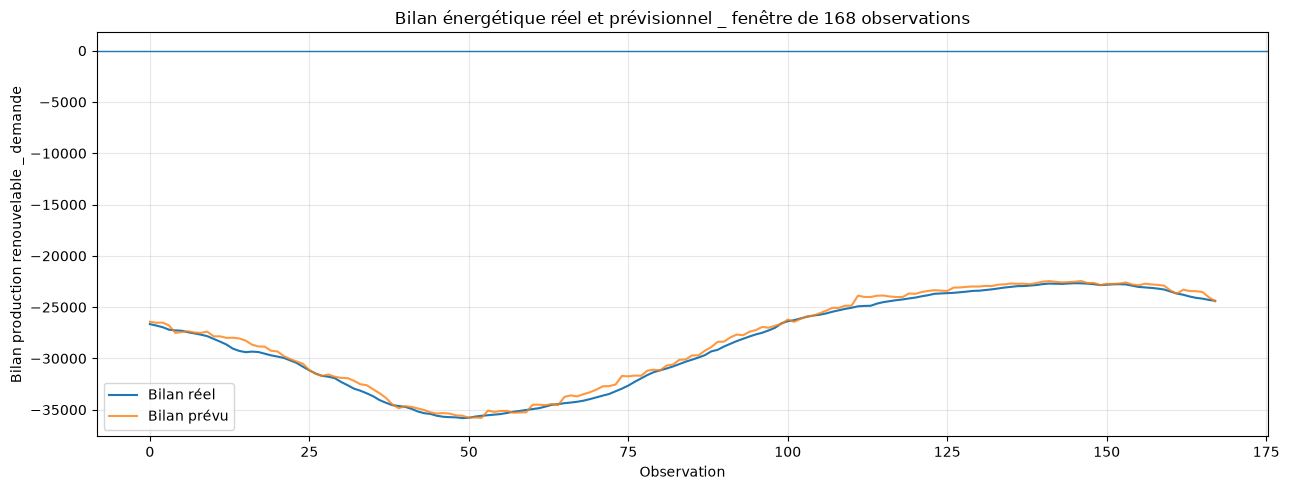

Figure enregistrée : c:\Users\celes\Desktop\PFE\figures\energy_balance_real_vs_predicted.png


In [29]:
# VISUALISATION DU BILAN RÉEL VS PRÉVU

n_display = min(
    168,
    len(energy_balance)
)

balance_display = (
    energy_balance
    .iloc[:n_display]
    .copy()
)


fig, ax = plt.subplots(
    figsize=(13, 5)
)

ax.plot(
    balance_display.index,
    balance_display["Balance_real"],
    label="Bilan réel",
    linewidth=1.5,
)

ax.plot(
    balance_display.index,
    balance_display["Balance_pred"],
    label="Bilan prévu",
    linewidth=1.5,
    alpha=0.8,
)

ax.axhline(
    0,
    linewidth=1,
)

ax.set_title(
    "Bilan énergétique réel et prévisionnel _ fenêtre de 168 observations"
)

ax.set_xlabel("Observation")
ax.set_ylabel("Bilan production renouvelable _ demande")

ax.grid(
    alpha=0.3
)

ax.legend()

fig.tight_layout()


# ENREGISTREMENT

FIG_ENERGY_BALANCE = (
    FIGURES_DIR
    / "energy_balance_real_vs_predicted.png"
)

fig.savefig(
    FIG_ENERGY_BALANCE,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


print(
    "Figure enregistrée :",
    FIG_ENERGY_BALANCE
)

## 19. Distribution du bilan énergétique

La définition des états « déficit », « équilibre » et « surplus » nécessite un
seuil autour de zéro.

Ce seuil ne doit pas être choisi arbitrairement.

Avant de définir les règles d'aide à la décision, la distribution complète des
bilans réel et prévisionnel est donc analysée afin de déterminer :

- leur valeur minimale et maximale ;
- leur position moyenne et médiane ;
- leur dispersion ;
- la proportion d'observations présentant naturellement un bilan positif ou
  négatif ;
- la fréquence des situations proches de l'équilibre.

Cette étape permet également de vérifier si les trois états envisagés sont
réellement représentés dans les données.

In [30]:
# DISTRIBUTION DU BILAN ÉNERGÉTIQUE

balance_statistics = (
    energy_balance[
        [
            "Balance_real",
            "Balance_pred",
        ]
    ]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99,
        ]
    )
)


print("DISTRIBUTION DU BILAN ÉNERGÉTIQUE")

display(
    balance_statistics.round(2)
)


print("\nRépartition du signe du bilan réel :")

print(
    "Bilan négatif :",
    (energy_balance["Balance_real"] < 0).sum()
)

print(
    "Bilan nul :",
    (energy_balance["Balance_real"] == 0).sum()
)

print(
    "Bilan positif :",
    (energy_balance["Balance_real"] > 0).sum()
)


print("\nProportions :")

print(
    "Déficit brut :",
    round(
        (
            energy_balance["Balance_real"] < 0
        ).mean() * 100,
        2
    ),
    "%"
)

print(
    "Surplus brut :",
    round(
        (
            energy_balance["Balance_real"] > 0
        ).mean() * 100,
        2
    ),
    "%"
)

DISTRIBUTION DU BILAN ÉNERGÉTIQUE


,Balance_real,Balance_pred
count,47043.00,47043.00
mean,-20425.01,-20484.43
std,6077.99,5893.51
min,-39814.00,-39882.18
1%,-35760.58,-35670.21
5%,-31230.80,-31010.61
10%,-27957.00,-27770.06
25%,-23951.50,-23856.11
50%,-20532.00,-20515.62
75%,-16828.00,-16981.92



Répartition du signe du bilan réel :
Bilan négatif : 47043
Bilan nul : 0
Bilan positif : 0

Proportions :
Déficit brut : 100.0 %
Surplus brut : 0.0 %


### Interprétation 

L'analyse de la distribution révèle une caractéristique importante du système
étudié : le bilan énergétique réel est négatif pour l'ensemble des
**47 043 observations** du jeu de test.

Le bilan réel varie entre environ **−39 814 et −3 601**, avec une valeur
médiane de **−20 532**.

Ainsi, dans le périmètre des données utilisées, la somme des productions
photovoltaïque et éolienne considérées ne suffit à aucun instant du jeu de test
à couvrir intégralement la demande électrique.

Cette observation ne signifie pas que le système électrique réel est
nécessairement en déficit. Le bilan construit ici ne considère que les deux
sources renouvelables étudiées dans le PFE. D'autres moyens de production,
les importations, le stockage ou d'autres mécanismes d'équilibrage peuvent
contribuer à satisfaire la demande réelle.

Par conséquent, une classification en « déficit / équilibre / surplus » serait
peu informative dans ce jeu de données puisque toutes les observations
appartiendraient à la même classe « déficit ».

La suite de l'analyse s'intéresse donc plutôt à **l'intensité du déficit
renouvelable**, afin de transformer les prévisions en information utile pour
l'aide à la décision.

## 20. Visualisation de la distribution du bilan

L'histogramme du bilan réel permet de compléter les statistiques descriptives
et de visualiser la fréquence des différents niveaux de déséquilibre.

La ligne verticale située à zéro représente l'équilibre théorique entre la
production renouvelable considérée et la demande.

Cette représentation est particulièrement utile pour déterminer si des
situations de surplus existent réellement dans le jeu de test et si une zone
d'équilibre peut être définie de manière pertinente.

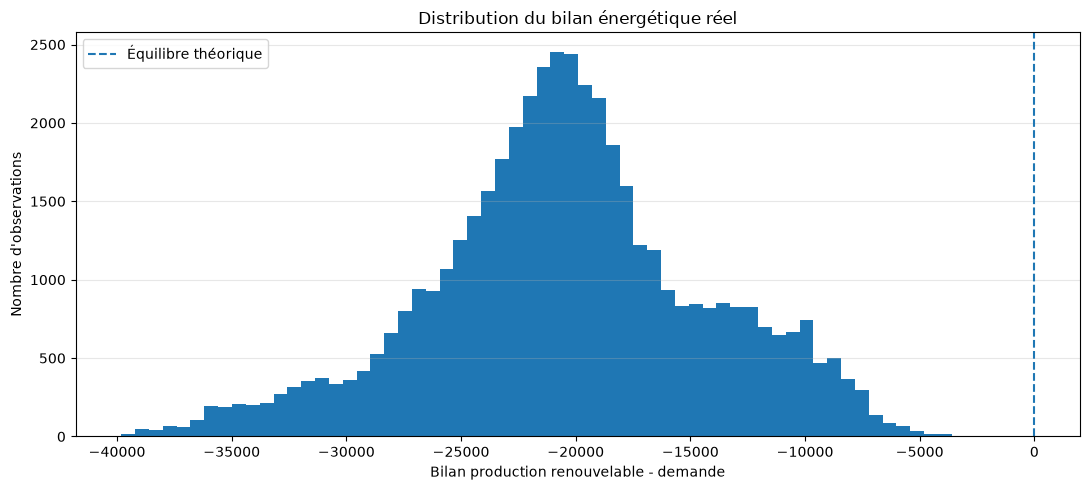

Figure enregistrée : c:\Users\celes\Desktop\PFE\figures\energy_balance_distribution.png


In [31]:
# DISTRIBUTION DU BILAN RÉEL

fig, ax = plt.subplots(
    figsize=(11, 5)
)

ax.hist(
    energy_balance["Balance_real"],
    bins=60,
)

ax.axvline(
    0,
    linestyle="--",
    linewidth=1.5,
    label="Équilibre théorique",
)

ax.set_title(
    "Distribution du bilan énergétique réel"
)

ax.set_xlabel(
    "Bilan production renouvelable - demande"
)

ax.set_ylabel(
    "Nombre d'observations"
)

ax.grid(
    axis="y",
    alpha=0.3,
)

ax.legend()

fig.tight_layout()


# ENREGISTREMENT

FIG_BALANCE_DISTRIBUTION = (
    FIGURES_DIR
    / "energy_balance_distribution.png"
)

fig.savefig(
    FIG_BALANCE_DISTRIBUTION,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


print(
    "Figure enregistrée :",
    FIG_BALANCE_DISTRIBUTION
)

## 21. Capacité à anticiper le sens du déséquilibre

Au-delà de l'erreur numérique, une information essentielle pour l'exploitation
opérationnelle est le **signe du bilan**.

Une prévision correcte du signe permet de distinguer deux situations
fondamentales :

- production renouvelable inférieure à la demande ;
- production renouvelable supérieure à la demande.

La concordance entre le signe du bilan prévu et celui du bilan réel est donc
mesurée avant l'introduction d'une éventuelle zone d'équilibre.

Cette analyse constitue une première mesure de l'utilité décisionnelle des
prévisions.

In [32]:
# CONCORDANCE DU SIGNE DU BILAN

real_sign = np.sign(
    energy_balance["Balance_real"]
)

pred_sign = np.sign(
    energy_balance["Balance_pred"]
)


sign_correct = (
    real_sign == pred_sign
)


sign_accuracy = (
    sign_correct.mean()
    * 100
)


print("ANTICIPATION DU SENS DU BILAN")

print(
    "Observations correctement anticipées :",
    sign_correct.sum()
)

print(
    "Nombre total d'observations :",
    len(sign_correct)
)

print(
    "Taux de concordance :",
    round(sign_accuracy, 2),
    "%"
)


sign_errors = (
    ~sign_correct
).sum()

print(
    "Erreurs de signe :",
    sign_errors
)

ANTICIPATION DU SENS DU BILAN
Observations correctement anticipées : 47043
Nombre total d'observations : 47043
Taux de concordance : 100.0 %
Erreurs de signe : 0


### Interprétation 

Le bilan prévisionnel possède le même signe que le bilan réel pour les
**47 043 observations**, soit un taux de concordance de **100 %**.

Ce résultat montre que le système identifie correctement l'existence d'un
déficit renouvelable sur l'ensemble du jeu de test.

Cependant, cette performance doit être interprétée avec prudence : puisque le
bilan réel est négatif dans 100 % des observations, la prédiction du seul signe
constitue ici un problème trivial et ne suffit pas à démontrer l'utilité
opérationnelle du système.

L'enjeu pertinent n'est donc pas de déterminer si un déficit existe, mais
d'anticiper **son intensité**.

La suite de l'étude transforme ainsi le problème en plusieurs niveaux de
déficit renouvelable afin d'obtenir une information décisionnelle plus
discriminante.

## 22. Taux de couverture renouvelable de la demande

Le bilan absolu permet de quantifier l'écart entre production renouvelable et
demande, mais son interprétation dépend directement de l'échelle des données.

Afin d'obtenir un indicateur plus facilement interprétable, un **taux de
couverture renouvelable** est calculé :

\[
Taux de couverture =frac{Production PV + Production éolienne}{Demande}times 100
\]

Un taux de 70 % signifie, par exemple, que les productions photovoltaïque et
éolienne considérées représentent l'équivalent de 70 % de la demande à
l'instant étudié.

Le taux de déficit complémentaire est défini par :

\[
Taux de déficit = 100 - Taux de couverture
\]

Deux versions sont calculées :

- le taux réel, utilisé pour l'évaluation ;
- le taux prévisionnel, disponible à partir des prédictions H+1.

Ces indicateurs ne représentent pas la couverture totale du système électrique,
puisque seules les productions photovoltaïque et éolienne étudiées dans ce PFE
sont prises en compte.

In [33]:
# TAUX DE COUVERTURE RENOUVELABLE

energy_balance["Coverage_real_pct"] = (
    energy_balance["Renewable_real"]
    / energy_balance["Demand_reel"]
    * 100
)

energy_balance["Coverage_pred_pct"] = (
    energy_balance["Renewable_pred"]
    / energy_balance["Demand_predit"]
    * 100
)


# TAUX DE DÉFICIT

energy_balance["Deficit_real_pct"] = (
    100
    - energy_balance["Coverage_real_pct"]
)

energy_balance["Deficit_pred_pct"] = (
    100
    - energy_balance["Coverage_pred_pct"]
)


print("COUVERTURE RENOUVELABLE DE LA DEMANDE")

display(
    energy_balance[
        [
            "Coverage_real_pct",
            "Coverage_pred_pct",
            "Deficit_real_pct",
            "Deficit_pred_pct",
        ]
    ]
    .describe(
        percentiles=[
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
        ]
    )
    .round(2)
)

COUVERTURE RENOUVELABLE DE LA DEMANDE


,Coverage_real_pct,Coverage_pred_pct,Deficit_real_pct,Deficit_pred_pct
count,47043.00,47043.00,47043.00,47043.00
mean,21.44,21.01,78.56,78.99
std,17.69,16.92,17.69,16.92
min,0.17,0.34,20.70,21.92
10%,3.35,3.61,51.26,53.12
25%,7.00,7.08,63.52,64.60
50%,14.01,14.03,85.99,85.97
75%,36.48,35.40,93.00,92.92
90%,48.74,46.88,96.65,96.39
max,79.30,78.08,99.83,99.66


### Interprétation 

Sur les **47 043 observations** du jeu de test, les productions photovoltaïque
et éolienne représentent en moyenne l'équivalent de **21,44 % de la demande
électrique**.

La médiane du taux de couverture est cependant plus faible, à environ
**14,01 %**. Cette différence entre moyenne et médiane traduit une distribution
asymétrique : certaines périodes de forte production renouvelable augmentent
sensiblement la couverture de la demande.

Le taux réel varie d'environ **0,17 % à 79,30 %**. La contribution des deux
sources renouvelables considérées est donc très variable selon les conditions
observées.

Le déficit renouvelable complémentaire atteint en moyenne **78,56 %** de la
demande. Cette valeur ne doit pas être interprétée comme un déficit du système
électrique global : elle représente uniquement la part de la demande qui n'est
pas couverte par les productions photovoltaïque et éolienne incluses dans
l'étude.

Les valeurs prévisionnelles présentent une distribution très proche des valeurs
réelles. Le taux de couverture prévu atteint en moyenne **21,01 %**, contre
**21,44 %** réellement observé, ce qui suggère une bonne restitution globale
du niveau de couverture renouvelable.

## 23. Évaluation du taux de couverture prévisionnel

L'intérêt opérationnel du système dépend de sa capacité à estimer non seulement
le bilan absolu, mais également la part de la demande pouvant être couverte par
les productions renouvelables considérées.

L'erreur entre le taux de couverture réel et le taux prévisionnel est donc
mesurée.

Cette analyse fournit une interprétation complémentaire aux métriques du bilan
énergétique, exprimée cette fois en points de pourcentage.

In [34]:
# ERREUR SUR LE TAUX DE COUVERTURE

coverage_mae = mean_absolute_error(
    energy_balance["Coverage_real_pct"],
    energy_balance["Coverage_pred_pct"],
)

coverage_rmse = np.sqrt(
    mean_squared_error(
        energy_balance["Coverage_real_pct"],
        energy_balance["Coverage_pred_pct"],
    )
)

coverage_r2 = r2_score(
    energy_balance["Coverage_real_pct"],
    energy_balance["Coverage_pred_pct"],
)


coverage_metrics = pd.DataFrame(
    {
        "Métrique": [
            "MAE_points_pct",
            "RMSE_points_pct",
            "R2",
        ],
        "Valeur": [
            coverage_mae,
            coverage_rmse,
            coverage_r2,
        ],
    }
)


print("PERFORMANCE DU TAUX DE COUVERTURE PRÉVISIONNEL")

display(
    coverage_metrics.round(4)
)

PERFORMANCE DU TAUX DE COUVERTURE PRÉVISIONNEL


,Métrique,Valeur
0,MAE_points_pct,1.4295
1,RMSE_points_pct,2.1369
2,R2,0.9854


### Interprétation 

La prévision du taux de couverture renouvelable présente une bonne précision
sur le jeu de test.

La **MAE est de 1,43 point de pourcentage** : en moyenne, le taux de couverture
prévu s'écarte donc du taux réellement observé d'environ 1,43 point.

La **RMSE atteint 2,14 points de pourcentage**, ce qui reste faible au regard
de l'étendue observée du taux de couverture.

Enfin, le coefficient de détermination atteint **\(R^2 = 0,9854\)**. Les
prévisions reproduisent ainsi une très grande partie de la variabilité du taux
de couverture renouvelable observé.

Ce résultat renforce l'intérêt opérationnel du système : les prévisions de
production photovoltaïque, de production éolienne et de demande peuvent être
combinées afin d'anticiper, à l'horizon H+1, non seulement un niveau de
production ou de consommation isolé, mais également la part de la demande
susceptible d'être couverte par les deux ressources renouvelables étudiées.

Cette information constitue la base du prototype d'aide à la décision développé
dans la section suivante.

In [35]:
# ENREGISTREMENT

COVERAGE_METRICS_FILE = (
    RESULTS_DIR
    / "renewable_coverage_metrics.csv"
)

coverage_metrics.to_csv(
    COVERAGE_METRICS_FILE,
    index=False,
)

print(
    "Résultats enregistrés :",
    COVERAGE_METRICS_FILE
)

Résultats enregistrés : c:\Users\celes\Desktop\PFE\results\renewable_coverage_metrics.csv


## 24. Prototype d'aide à la décision énergétique

L'objectif final n'est pas uniquement de produire une prévision numérique,
mais de transformer cette prévision en information facilement exploitable.

Un prototype d'aide à la décision est donc construit à partir du taux de
couverture renouvelable prévu à l'horizon H+1.

Quatre niveaux indicatifs sont utilisés :

- **couverture très faible** : moins de 10 % ;
- **couverture faible** : de 10 % à moins de 25 % ;
- **couverture modérée** : de 25 % à moins de 50 % ;
- **couverture élevée** : au moins 50 %.

Ces seuils ne correspondent pas à des normes réglementaires ou à des règles
officielles d'exploitation du réseau. Ils constituent des **seuils
illustratifs**, utilisés pour démontrer comment les résultats du modèle
prédictif peuvent être transformés en information décisionnelle.

Dans une application opérationnelle réelle, ces seuils devraient être définis
avec les gestionnaires du système énergétique en fonction notamment des
capacités de stockage, des autres moyens de production, des possibilités
d'importation, des coûts et des contraintes du réseau.

In [36]:
# CLASSIFICATION DU TAUX DE COUVERTURE

def classify_coverage(value):
    
    if value < 10:
        return "Très faible"
    
    elif value < 25:
        return "Faible"
    
    elif value < 50:
        return "Modérée"
    
    else:
        return "Élevée"


energy_balance["Coverage_level_real"] = (
    energy_balance["Coverage_real_pct"]
    .apply(classify_coverage)
)

energy_balance["Coverage_level_pred"] = (
    energy_balance["Coverage_pred_pct"]
    .apply(classify_coverage)
)


print("NIVEAUX DE COUVERTURE RENOUVELABLE")

print("\nNiveaux réels :")

display(
    energy_balance[
        "Coverage_level_real"
    ]
    .value_counts()
    .reindex(
        [
            "Très faible",
            "Faible",
            "Modérée",
            "Élevée",
        ],
        fill_value=0,
    )
    .to_frame("Nombre")
)


print("\nNiveaux prévus :")

display(
    energy_balance[
        "Coverage_level_pred"
    ]
    .value_counts()
    .reindex(
        [
            "Très faible",
            "Faible",
            "Modérée",
            "Élevée",
        ],
        fill_value=0,
    )
    .to_frame("Nombre")
)

NIVEAUX DE COUVERTURE RENOUVELABLE

Niveaux réels :


,Nombre
Coverage_level_real,
Très faible,16614
Faible,13843
Modérée,12402
Élevée,4184



Niveaux prévus :


,Nombre
Coverage_level_pred,
Très faible,16537
Faible,14074
Modérée,13130
Élevée,3302


## 25. Évaluation de la classification décisionnelle

Une bonne estimation numérique du taux de couverture ne garantit pas
nécessairement que le système attribue correctement le niveau décisionnel.

Les niveaux calculés à partir des observations réelles sont donc comparés aux
niveaux déterminés à partir des prévisions H+1.

Le taux de concordance mesure la proportion d'observations pour lesquelles le
système anticipe correctement la catégorie de couverture renouvelable.

Une matrice de confusion permet ensuite d'identifier les catégories entre
lesquelles se produisent les erreurs.

In [37]:
# CONCORDANCE DES NIVEAUX DE COUVERTURE

coverage_level_correct = (
    energy_balance["Coverage_level_real"]
    == energy_balance["Coverage_level_pred"]
)

coverage_level_accuracy = (
    coverage_level_correct.mean()
    * 100
)


print("ÉVALUATION DE L'AIDE À LA DÉCISION")

print(
    "Classifications correctes :",
    coverage_level_correct.sum()
)

print(
    "Nombre total d'observations :",
    len(coverage_level_correct)
)

print(
    "Taux de concordance :",
    round(
        coverage_level_accuracy,
        2,
    ),
    "%"
)

ÉVALUATION DE L'AIDE À LA DÉCISION
Classifications correctes : 43438
Nombre total d'observations : 47043
Taux de concordance : 92.34 %


In [38]:
# MATRICE DE CONFUSION DES NIVEAUX

coverage_order = [
    "Très faible",
    "Faible",
    "Modérée",
    "Élevée",
]


coverage_confusion = pd.crosstab(
    energy_balance["Coverage_level_real"],
    energy_balance["Coverage_level_pred"],
    rownames=["Niveau réel"],
    colnames=["Niveau prévu"],
)


coverage_confusion = (
    coverage_confusion
    .reindex(
        index=coverage_order,
        columns=coverage_order,
        fill_value=0,
    )
)


print("MATRICE DE CONFUSION")

display(
    coverage_confusion
)

MATRICE DE CONFUSION


Niveau prévu,Très faible,Faible,Modérée,Élevée
Niveau réel,,,,
Très faible,15682,932,0,0
Faible,855,12669,319,0
Modérée,0,473,11857,72
Élevée,0,0,954,3230


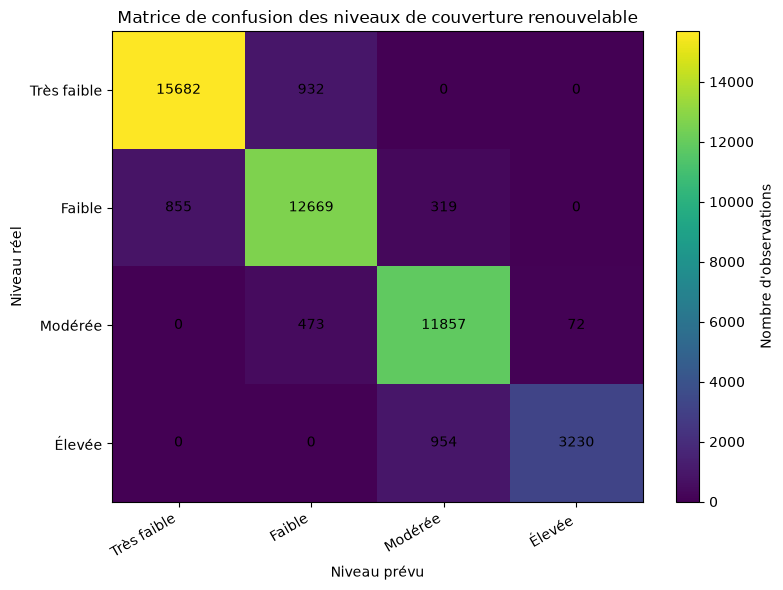

Figure enregistrée : c:\Users\celes\Desktop\PFE\figures\renewable_coverage_confusion_matrix.png


In [39]:
# FIGURE - MATRICE DE CONFUSION

fig, ax = plt.subplots(
    figsize=(8, 6)
)

image = ax.imshow(
    coverage_confusion.values,
    aspect="auto",
)

ax.set_xticks(
    range(len(coverage_order))
)

ax.set_yticks(
    range(len(coverage_order))
)

ax.set_xticklabels(
    coverage_order,
    rotation=30,
    ha="right",
)

ax.set_yticklabels(
    coverage_order
)

ax.set_xlabel(
    "Niveau prévu"
)

ax.set_ylabel(
    "Niveau réel"
)

ax.set_title(
    "Matrice de confusion des niveaux de couverture renouvelable"
)


# Valeurs dans les cases

for i in range(len(coverage_order)):
    for j in range(len(coverage_order)):
        
        ax.text(
            j,
            i,
            coverage_confusion.iloc[i, j],
            ha="center",
            va="center",
        )


fig.colorbar(
    image,
    ax=ax,
    label="Nombre d'observations",
)

fig.tight_layout()


# ENREGISTREMENT

FIG_COVERAGE_CONFUSION = (
    FIGURES_DIR
    / "renewable_coverage_confusion_matrix.png"
)

fig.savefig(
    FIG_COVERAGE_CONFUSION,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


print(
    "Figure enregistrée :",
    FIG_COVERAGE_CONFUSION
)

### Interprétation de l'aide à la décision

Le système obtient un **taux de concordance de 92,34 %** entre les niveaux de
couverture renouvelable réellement observés et ceux déterminés à partir des
prévisions à l'horizon H+1. Ainsi, **43 438 observations sur 47 043** sont
affectées à la bonne catégorie.

La matrice de confusion montre également que les erreurs de classification
restent essentiellement concentrées entre des **niveaux adjacents**. Aucun cas
réel de couverture « Très faible » n'est directement classé comme « Modérée »
ou « Élevée ». De même, aucun cas de couverture réelle « Élevée » n'est
classé comme « Très faible » ou « Faible ».

Les principales confusions concernent notamment :

- 932 situations « Très faibles » classées « Faibles » ;
- 855 situations « Faibles » classées « Très faibles » ;
- 473 situations « Modérées » classées « Faibles » ;
- 954 situations « Élevées » classées « Modérées ».

Cette dernière confusion explique en partie pourquoi le nombre de situations
de couverture élevée est sous-estimé par le système : **3 302 situations**
sont prévues comme « Élevées », contre **4 184 réellement observées**.

Ces résultats montrent que les erreurs du système correspondent principalement
à un déplacement d'un niveau de couverture vers le niveau immédiatement voisin,
plutôt qu'à des erreurs extrêmes de classification.

Le prototype permet ainsi de transformer les prévisions individuelles de
production photovoltaïque, de production éolienne et de demande électrique en
une information synthétique sur la capacité des deux ressources renouvelables
étudiées à contribuer à la couverture de la demande à l'horizon H+1.

Il ne constitue pas un système complet d'optimisation ou de pilotage du réseau
électrique. Il représente une **couche d'aide à la décision**, destinée à
illustrer comment les prévisions issues des modèles d'intelligence artificielle
peuvent être exploitées pour anticiper les situations de faible ou de forte
contribution renouvelable.

# Partie III - Couplage climat-énergie et analyse de sensibilité

## 26. Analyse de sensibilité énergétique aux évolutions climatiques

Les analyses précédentes ont permis d'étudier les tendances historiques de
plusieurs variables climatiques et météorologiques, puis de construire des
modèles de prévision à court terme de la production photovoltaïque, de la
production éolienne et de la demande électrique.

Cette section cherche maintenant à établir un lien plus direct entre ces deux
dimensions du projet.

L'objectif est d'étudier comment des modifications des conditions de
température, de rayonnement solaire et de vent peuvent affecter les variables
énergétiques et, par conséquent, la capacité des productions renouvelables
étudiées à contribuer à la couverture de la demande.

L'analyse repose sur des **scénarios de sensibilité** appliqués aux données
météorologiques observées. Ces scénarios ne constituent pas des projections
climatiques officielles et ne doivent pas être interprétés comme une prévision
du climat futur.

Ils permettent de répondre à une question expérimentale :

> **Comment le système énergétique étudié réagirait-il, toutes choses égales
> par ailleurs, à une modification contrôlée de certaines conditions
> climatiques ?**

Cette approche permet ainsi d'explorer le lien entre changement des conditions
climatiques, production renouvelable, demande électrique et équilibre
énergétique.

## 27. Définition des scénarios de sensibilité

Trois facteurs directement liés aux ressources énergétiques étudiées sont
considérés :

- la **température**, susceptible notamment d'influencer la demande électrique
  et le comportement de la production photovoltaïque ;
- le **rayonnement solaire**, directement associé au potentiel de production
  photovoltaïque ;
- le **vent**, directement associé au potentiel de production éolienne.

Pour chaque facteur, plusieurs perturbations sont appliquées autour des
conditions observées.

Les scénarios sont volontairement simples et interprétables. Ils permettent
d'isoler l'effet d'une variable en maintenant les autres constantes selon le
principe *ceteris paribus*.

Les amplitudes utilisées constituent des hypothèses expérimentales de
sensibilité. Elles ne représentent ni des scénarios SSP/RCP, ni des projections
climatiques officielles.

In [40]:
# SCÉNARIOS DE SENSIBILITÉ CLIMATIQUE

climate_scenarios = {
    
    "Température": [
        -2.0,
        -1.0,
        0.0,
        1.0,
        2.0,
        3.0,
    ],
    
    "Rayonnement": [
        -20,
        -10,
        0,
        10,
        20,
    ],
    
    "Vent": [
        -20,
        -10,
        0,
        10,
        20,
    ],
}


print("SCÉNARIOS DE SENSIBILITÉ CLIMATIQUE")

print("\nTempérature _ variation absolue (°C)")
print(climate_scenarios["Température"])

print("\nRayonnement solaire _ variation relative (%)")
print(climate_scenarios["Rayonnement"])

print("\nVent _ variation relative (%)")
print(climate_scenarios["Vent"])

SCÉNARIOS DE SENSIBILITÉ CLIMATIQUE

Température _ variation absolue (°C)
[-2.0, -1.0, 0.0, 1.0, 2.0, 3.0]

Rayonnement solaire _ variation relative (%)
[-20, -10, 0, 10, 20]

Vent _ variation relative (%)
[-20, -10, 0, 10, 20]


## 28. Compatibilité temporelle entre données climatiques et énergétiques

L'analyse climatique et la modélisation énergétique reposent sur des sources
de données distinctes.

Avant d'étudier leurs relations, il est nécessaire de vérifier l'existence
d'une période temporelle commune entre les observations climatiques NASA POWER
et les données énergétiques utilisées dans le système prédictif.

Cette étape évite d'associer artificiellement des observations provenant de
périodes différentes.

In [41]:
# PÉRIODE CLIMATIQUE NASA

print("PÉRIODE DES DONNÉES CLIMATIQUES")

print(
    "Début :",
    nasa["Date"].min()
)

print(
    "Fin   :",
    nasa["Date"].max()
)

print(
    "Nombre d'observations :",
    len(nasa)
)

PÉRIODE DES DONNÉES CLIMATIQUES
Début : 1990-01-01 00:00:00
Fin   : 2025-12-31 00:00:00
Nombre d'observations : 13149


In [42]:
# PÉRIODE DES DONNÉES ÉNERGÉTIQUES

energy_predictions["Time"] = pd.to_datetime(
    energy_predictions["Time"],
    errors="coerce"
)

print("PÉRIODE DES DONNÉES ÉNERGÉTIQUES")

print(
    "Début :",
    energy_predictions["Time"].min()
)

print(
    "Fin   :",
    energy_predictions["Time"].max()
)

print(
    "Nombre d'observations :",
    len(energy_predictions)
)

print(
    "Timestamps invalides :",
    energy_predictions["Time"].isna().sum()
)

PÉRIODE DES DONNÉES ÉNERGÉTIQUES
Début : 2021-07-21 14:45:00
Fin   : 2021-12-31 22:55:00
Nombre d'observations : 47043
Timestamps invalides : 0


### Vérification de la période commune

Les données climatiques NASA POWER couvrent la période 1990-2025, tandis que
les prédictions énergétiques correspondent au jeu de test final du pipeline
principal.

La comparaison des bornes temporelles permet de déterminer s'il existe une
période commune permettant d'associer directement observations climatiques et
énergétiques.

Cette vérification est indispensable avant toute analyse de relation
climat-énergie : des données provenant de périodes différentes ne doivent pas
être fusionnées artificiellement.

In [43]:
# PÉRIODE TEMPORELLE COMMUNE

climate_start = nasa["Date"].min()
climate_end = nasa["Date"].max()

energy_start = energy_predictions["Time"].min()
energy_end = energy_predictions["Time"].max()


overlap_start = max(
    climate_start,
    energy_start
)

overlap_end = min(
    climate_end,
    energy_end
)


print("CHEVAUCHEMENT TEMPOREL")

print(
    "NASA POWER :",
    climate_start,
    "→",
    climate_end
)

print(
    "Énergie    :",
    energy_start,
    "→",
    energy_end
)


if overlap_start <= overlap_end:

    print(
        "\nPériode commune :",
        overlap_start,
        "→",
        overlap_end
    )

    print(
        "Durée approximative :",
        overlap_end - overlap_start
    )

else:

    print(
        "\nAucune période commune disponible."
    )

CHEVAUCHEMENT TEMPOREL
NASA POWER : 1990-01-01 00:00:00 → 2025-12-31 00:00:00
Énergie    : 2021-07-21 14:45:00 → 2021-12-31 22:55:00

Période commune : 2021-07-21 14:45:00 → 2021-12-31 22:55:00
Durée approximative : 163 days 08:10:00


## 29. Construction d'un jeu commun climat-énergie

Les données climatiques NASA POWER sont disponibles à une résolution
quotidienne, tandis que les données énergétiques utilisées pour la prévision
présentent une résolution infra-journalière.

Afin de rendre les deux sources comparables, les variables énergétiques sont
agrégées quotidiennement sur la période commune.

Pour cette analyse, les valeurs moyennes quotidiennes sont utilisées pour
caractériser :

- la production photovoltaïque ;
- la production éolienne ;
- la demande électrique ;
- le taux de couverture renouvelable.

Les données obtenues sont ensuite associées aux observations climatiques NASA
POWER à partir de leur date commune.

Cette opération permet de construire un jeu d'analyse dans lequel les
conditions météorologiques observées et l'état du système énergétique
correspondent effectivement aux mêmes journées.

In [44]:
# AGRÉGATION QUOTIDIENNE DES DONNÉES ÉNERGÉTIQUES

energy_climate = energy_balance.copy()

# Création d'une date journalière sans composante horaire
energy_climate["Date"] = (
    pd.to_datetime(energy_climate["Time"])
    .dt.normalize()
)

# Variables énergétiques retenues
daily_energy_columns = [
    "PV_reel",
    "Wind_reel",
    "Demand_reel",
    "Renewable_real",
    "Coverage_real_pct",
]

# Agrégation quotidienne
energy_daily = (
    energy_climate
    .groupby("Date")[daily_energy_columns]
    .mean()
    .reset_index()
)

print("DONNÉES ÉNERGÉTIQUES AGRÉGÉES PAR JOUR")

print("Nombre de jours :", len(energy_daily))
print(
    "Période :",
    energy_daily["Date"].min(),
    "→",
    energy_daily["Date"].max()
)

display(energy_daily.head())

DONNÉES ÉNERGÉTIQUES AGRÉGÉES PAR JOUR
Nombre de jours : 164
Période : 2021-07-21 00:00:00 → 2021-12-31 00:00:00


,Date,PV_reel,Wind_reel,Demand_reel,Renewable_real,Coverage_real_pct
0,2021-07-21,2807.918919,3053.243243,36944.819820,5861.162162,15.366311
1,2021-07-22,4638.993056,1828.381944,31969.465278,6467.375000,19.813143
2,2021-07-23,4585.562500,1417.295139,31286.878472,6002.857639,18.951354
3,2021-07-24,3655.555556,1666.447917,28528.149306,5322.003472,18.896227
4,2021-07-25,4202.840278,2392.593750,27313.934028,6595.434028,24.310157


## 30. Extraction des observations climatiques de la période énergétique

Les observations NASA POWER sont maintenant limitées à la période couverte
par les données énergétiques.

Les quatre variables climatiques retenues sont :

- `ALLSKY_SFC_SW_DWN` : rayonnement solaire reçu à la surface ;
- `T2M` : température de l'air à 2 mètres ;
- `RH2M` : humidité relative à 2 mètres ;
- `WS10M` : vitesse du vent à 10 mètres.

L'humidité est conservée dans l'analyse afin de ne pas réduire les conditions
atmosphériques aux seules variables directement associées au photovoltaïque
et à l'éolien.

In [45]:
# PRÉPARATION DES DONNÉES CLIMATIQUES

climate_daily = nasa[
    [
        "Date",
        "ALLSKY_SFC_SW_DWN",
        "T2M",
        "RH2M",
        "WS10M",
    ]
].copy()

climate_daily["Date"] = pd.to_datetime(
    climate_daily["Date"]
).dt.normalize()

# Restriction à la période énergétique
climate_daily = climate_daily[
    (climate_daily["Date"] >= energy_daily["Date"].min())
    &
    (climate_daily["Date"] <= energy_daily["Date"].max())
].copy()

print("DONNÉES CLIMATIQUES SUR LA PÉRIODE COMMUNE")

print("Nombre de jours :", len(climate_daily))

print(
    "Période :",
    climate_daily["Date"].min(),
    "→",
    climate_daily["Date"].max()
)

display(climate_daily.head())

DONNÉES CLIMATIQUES SUR LA PÉRIODE COMMUNE
Nombre de jours : 164
Période : 2021-07-21 00:00:00 → 2021-12-31 00:00:00


,Date,ALLSKY_SFC_SW_DWN,T2M,RH2M,WS10M
11524,2021-07-21,7.8305,30.32,29.72,2.96
11525,2021-07-22,6.9250,33.93,24.76,2.88
11526,2021-07-23,7.3714,34.88,25.12,4.30
11527,2021-07-24,6.4670,31.41,33.43,4.11
11528,2021-07-25,7.8689,27.70,36.69,4.53


## 31. Fusion des données climatiques et énergétiques

Les observations climatiques et énergétiques étant désormais exprimées à la
même résolution quotidienne, elles peuvent être associées selon leur date.

Une jointure interne est utilisée afin de conserver uniquement les journées
pour lesquelles les deux sources disposent simultanément d'informations.

Le jeu obtenu constitue la base de l'analyse empirique des relations entre
conditions climatiques et comportement énergétique.

In [46]:
# FUSION CLIMAT - ÉNERGIE

climate_energy = pd.merge(
    climate_daily,
    energy_daily,
    on="Date",
    how="inner",
    validate="one_to_one",
)

print("JEU COMMUN CLIMAT - ÉNERGIE")

print(
    "Nombre de journées communes :",
    len(climate_energy)
)

print(
    "Période :",
    climate_energy["Date"].min(),
    "->",
    climate_energy["Date"].max()
)

print(
    "Valeurs manquantes :",
    climate_energy.isna().sum().sum()
)

display(climate_energy.head())

JEU COMMUN CLIMAT - ÉNERGIE
Nombre de journées communes : 164
Période : 2021-07-21 00:00:00 -> 2021-12-31 00:00:00
Valeurs manquantes : 0


,Date,ALLSKY_SFC_SW_DWN,T2M,RH2M,WS10M,PV_reel,Wind_reel,Demand_reel,Renewable_real,Coverage_real_pct
0,2021-07-21,7.8305,30.32,29.72,2.96,2807.918919,3053.243243,36944.819820,5861.162162,15.366311
1,2021-07-22,6.9250,33.93,24.76,2.88,4638.993056,1828.381944,31969.465278,6467.375000,19.813143
2,2021-07-23,7.3714,34.88,25.12,4.30,4585.562500,1417.295139,31286.878472,6002.857639,18.951354
3,2021-07-24,6.4670,31.41,33.43,4.11,3655.555556,1666.447917,28528.149306,5322.003472,18.896227
4,2021-07-25,7.8689,27.70,36.69,4.53,4202.840278,2392.593750,27313.934028,6595.434028,24.310157


In [47]:
# CONTRÔLE DU JEU CLIMAT - ÉNERGIE

print("CONTRÔLE DU JEU CLIMAT - ÉNERGIE")

print("\nDimensions :", climate_energy.shape)

print("\nColonnes :")
for column in climate_energy.columns:
    print("-", column)

print("\nValeurs manquantes par variable :")
display(
    climate_energy
    .isna()
    .sum()
    .to_frame("Valeurs_manquantes")
)

CONTRÔLE DU JEU CLIMAT - ÉNERGIE

Dimensions : (164, 10)

Colonnes :
- Date
- ALLSKY_SFC_SW_DWN
- T2M
- RH2M
- WS10M
- PV_reel
- Wind_reel
- Demand_reel
- Renewable_real
- Coverage_real_pct

Valeurs manquantes par variable :


,Valeurs_manquantes
Date,0
ALLSKY_SFC_SW_DWN,0
T2M,0
RH2M,0
WS10M,0
PV_reel,0
Wind_reel,0
Demand_reel,0
Renewable_real,0
Coverage_real_pct,0


## 32. Analyse des relations entre climat et système énergétique

Après harmonisation temporelle des deux sources, le jeu commun permet
d'étudier les associations entre conditions météorologiques et comportement
du système énergétique sur les 164 journées disponibles.

Trois relations présentent un intérêt particulier au regard du fonctionnement
physique du système :

- le rayonnement solaire et la production photovoltaïque ;
- la vitesse du vent et la production éolienne ;
- la température et la demande électrique.

L'effet des conditions météorologiques sur le taux de couverture de la demande
par les productions renouvelables est également étudié.

Deux coefficients de corrélation sont calculés :

- **Pearson**, qui mesure principalement l'intensité d'une relation linéaire ;
- **Spearman**, qui mesure une association monotone et est moins dépendant de
  l'hypothèse de linéarité.

Ces coefficients décrivent des associations statistiques observées sur la
période commune. Ils ne doivent pas être interprétés comme une démonstration
de causalité, notamment en raison de la saisonnalité et de la durée limitée de
la période énergétique disponible.

In [48]:
# CORRÉLATIONS CLIMAT - ÉNERGIE

from scipy.stats import pearsonr, spearmanr

relations = [
    {
        "Relation": "Rayonnement solaire → Production PV",
        "Climate_variable": "ALLSKY_SFC_SW_DWN",
        "Energy_variable": "PV_reel",
    },
    {
        "Relation": "Vitesse du vent → Production éolienne",
        "Climate_variable": "WS10M",
        "Energy_variable": "Wind_reel",
    },
    {
        "Relation": "Température → Demande électrique",
        "Climate_variable": "T2M",
        "Energy_variable": "Demand_reel",
    },
]

correlation_results = []

for relation in relations:

    x = climate_energy[relation["Climate_variable"]]
    y = climate_energy[relation["Energy_variable"]]

    pearson_r, pearson_p = pearsonr(x, y)
    spearman_r, spearman_p = spearmanr(x, y)

    correlation_results.append({
        "Relation": relation["Relation"],
        "Pearson_r": pearson_r,
        "Pearson_p": pearson_p,
        "Spearman_rho": spearman_r,
        "Spearman_p": spearman_p,
    })

correlation_results = pd.DataFrame(correlation_results)

print("RELATIONS CLIMAT - ÉNERGIE")

display(
    correlation_results.round(4)
)

RELATIONS CLIMAT - ÉNERGIE


,Relation,Pearson_r,Pearson_p,Spearman_rho,Spearman_p
0,Rayonnement solaire → Production PV,0.7415,0.0000,0.7613,0.0000
1,Vitesse du vent → Production éolienne,-0.1599,0.0408,-0.1416,0.0705
2,Température → Demande électrique,0.7080,0.0000,0.6962,0.0000


## 33. Conditions météorologiques et couverture renouvelable

La production renouvelable ne constitue pas à elle seule un indicateur
suffisant de l'équilibre énergétique : elle doit être mise en perspective avec
la demande électrique.

Le taux de couverture renouvelable représente la part de la demande pouvant
être couverte par les productions photovoltaïque et éolienne considérées dans
le système.

L'analyse suivante étudie donc l'association entre les principales variables
météorologiques et ce taux de couverture.

In [49]:
# CLIMAT ET COUVERTURE RENOUVELABLE

coverage_relations = {
    "Rayonnement solaire": "ALLSKY_SFC_SW_DWN",
    "Température": "T2M",
    "Humidité": "RH2M",
    "Vitesse du vent": "WS10M",
}

coverage_results = []

for label, variable in coverage_relations.items():

    pearson_r, pearson_p = pearsonr(
        climate_energy[variable],
        climate_energy["Coverage_real_pct"]
    )

    spearman_r, spearman_p = spearmanr(
        climate_energy[variable],
        climate_energy["Coverage_real_pct"]
    )

    coverage_results.append({
        "Variable climatique": label,
        "Pearson_r": pearson_r,
        "Pearson_p": pearson_p,
        "Spearman_rho": spearman_r,
        "Spearman_p": spearman_p,
    })

coverage_results = pd.DataFrame(coverage_results)

print("CLIMAT ET TAUX DE COUVERTURE RENOUVELABLE")

display(
    coverage_results.round(4)
)

CLIMAT ET TAUX DE COUVERTURE RENOUVELABLE


,Variable climatique,Pearson_r,Pearson_p,Spearman_rho,Spearman_p
0,Rayonnement solaire,0.2631,0.0007,0.2948,0.0001
1,Température,0.2815,0.0003,0.2972,0.0001
2,Humidité,-0.2575,0.0009,-0.2791,0.0003
3,Vitesse du vent,-0.0325,0.6792,-0.0137,0.8620


### Interprétation des relations avec le taux de couverture renouvelable

Les corrélations avec le taux de couverture renouvelable sont globalement plus modérées.

Le **rayonnement solaire** présente une association positive avec le taux de couverture (`r = 0,2631`, `ρ = 0,2948`), statistiquement significative. Une disponibilité solaire plus importante tend donc à être associée à une meilleure couverture de la demande par les productions renouvelables considérées.

La **température** présente également une association positive modérée (`r = 0,2815`, `ρ = 0,2972`). Ce résultat ne doit cependant pas être interprété comme un effet causal direct de la température sur la couverture : la température est elle-même liée à la saisonnalité, au rayonnement solaire et à l'évolution de la demande.

L'**humidité relative** présente une association négative modérée avec la couverture (`r = -0,2575`, `ρ = -0,2791`), statistiquement significative sur la période analysée.

En revanche, la **vitesse du vent à 10 m ne présente pratiquement aucune association avec le taux de couverture renouvelable** (`r = -0,0325`, `ρ = -0,0137`), avec des p-values largement supérieures à 0,05. Ce résultat est cohérent avec la faible relation précédemment observée entre cette variable météorologique et la production éolienne.

Ces résultats montrent que le rayonnement solaire constitue, parmi les variables étudiées, un indicateur météorologique particulièrement pertinent pour expliquer la composante photovoltaïque du système. Ils soulignent également les limites d'une analyse reposant uniquement sur le vent à 10 m pour représenter le potentiel éolien exploitable.

In [50]:
# FIGURES DES RELATIONS CLIMAT - ÉNERGIE

from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

figures_dir = Path("../figures")
figures_dir.mkdir(parents=True, exist_ok=True)


def plot_climate_energy_relation(
    dataframe,
    x_column,
    y_column,
    x_label,
    y_label,
    title,
    filename
):

    x = dataframe[x_column].to_numpy()
    y = dataframe[y_column].to_numpy()

    # Régression linéaire uniquement comme aide visuelle
    slope, intercept = np.polyfit(x, y, 1)

    x_line = np.linspace(
        x.min(),
        x.max(),
        200
    )

    y_line = slope * x_line + intercept

    pearson_r, _ = pearsonr(x, y)
    spearman_r, _ = spearmanr(x, y)

    plt.figure(figsize=(9, 6))

    plt.scatter(
        x,
        y,
        alpha=0.65
    )

    plt.plot(
        x_line,
        y_line,
        linewidth=2
    )

    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.title(title)

    plt.text(
        0.03,
        0.95,
        f"Pearson r = {pearson_r:.3f}\n"
        f"Spearman ρ = {spearman_r:.3f}",
        transform=plt.gca().transAxes,
        verticalalignment="top",
        bbox=dict(
            boxstyle="round",
            alpha=0.15
        )
    )

    plt.grid(
        alpha=0.25
    )

    plt.tight_layout()

    output_path = figures_dir / filename

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print(
        "Figure enregistrée :",
        output_path
    )

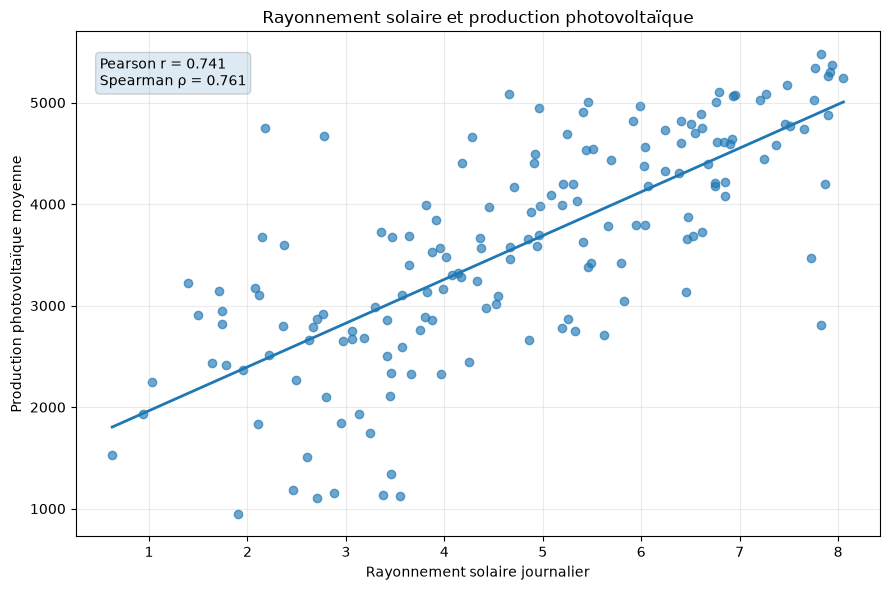

Figure enregistrée : ..\figures\climate_solar_vs_pv.png


In [51]:
# RAYONNEMENT SOLAIRE ET PRODUCTION PHOTOVOLTAÏQUE

plot_climate_energy_relation(
    climate_energy,
    "ALLSKY_SFC_SW_DWN",
    "PV_reel",
    "Rayonnement solaire journalier",
    "Production photovoltaïque moyenne",
    "Rayonnement solaire et production photovoltaïque",
    "climate_solar_vs_pv.png"
)

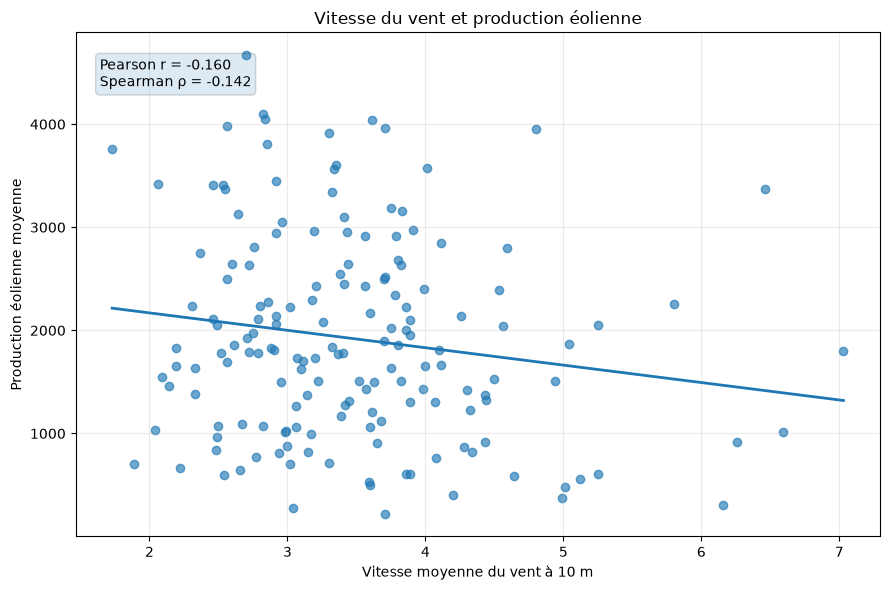

Figure enregistrée : ..\figures\climate_wind_vs_wind_generation.png


In [52]:
# VITESSE DU VENT ET PRODUCTION ÉOLIENNE

plot_climate_energy_relation(
    climate_energy,
    "WS10M",
    "Wind_reel",
    "Vitesse moyenne du vent à 10 m",
    "Production éolienne moyenne",
    "Vitesse du vent et production éolienne",
    "climate_wind_vs_wind_generation.png"
)

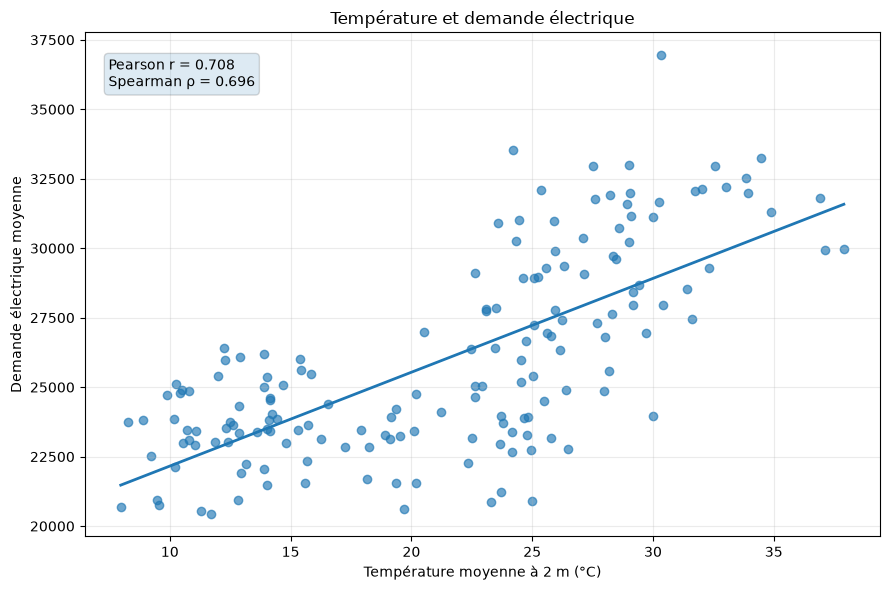

Figure enregistrée : ..\figures\climate_temperature_vs_demand.png


In [53]:
# TEMPÉRATURE ET DEMANDE ÉLECTRIQUE

plot_climate_energy_relation(
    climate_energy,
    "T2M",
    "Demand_reel",
    "Température moyenne à 2 m (°C)",
    "Demande électrique moyenne",
    "Température et demande électrique",
    "climate_temperature_vs_demand.png"
)

### Interprétation des relations climat-énergie

L'analyse met en évidence des comportements contrastés selon la composante énergétique étudiée.

Le **rayonnement solaire présente une forte association positive avec la production photovoltaïque**, avec un coefficient de Pearson de **0,7415** et un coefficient de Spearman de **0,7613**. Les deux relations sont statistiquement significatives (`p < 0,001`). Ce résultat est cohérent avec le fonctionnement physique des installations photovoltaïques : sur la période étudiée, les journées caractérisées par un rayonnement solaire plus important sont généralement associées à une production photovoltaïque plus élevée.

La relation entre la **vitesse du vent à 10 m et la production éolienne** est en revanche faible et négative. Le coefficient de Pearson atteint seulement **-0,1599** (`p = 0,0408`), tandis que la corrélation de Spearman est de **-0,1416** et n'est pas significative au seuil de 5 % (`p = 0,0705`). Ces résultats ne permettent donc pas de conclure qu'une augmentation de la vitesse du vent mesurée par NASA POWER entraîne une diminution de la production éolienne. Plusieurs facteurs peuvent expliquer cette faible correspondance, notamment l'utilisation d'une vitesse du vent mesurée à **10 m**, alors que les turbines exploitent le vent à une hauteur de moyeu nettement supérieure, ainsi que le caractère agrégé des données de production éolienne.

Enfin, une **forte association positive est observée entre la température et la demande électrique**. Les coefficients de Pearson (**0,7080**) et de Spearman (**0,6962**) sont tous deux élevés et statistiquement significatifs (`p < 0,001`). Sur la période commune étudiée, les températures les plus élevées sont donc généralement associées à une demande électrique plus importante. Cette association peut notamment refléter des usages thermosensibles de l'électricité. Elle doit cependant être interprétée avec prudence, car la période disponible s'étend seulement de juillet à décembre 2021 et plusieurs facteurs saisonniers ou socio-économiques peuvent également influencer la demande.

Ces résultats confirment ainsi l'intérêt d'intégrer les conditions météorologiques dans l'analyse du système énergétique, tout en montrant que leur influence apparente dépend fortement de la variable considérée et de la représentativité des données disponibles.

## 34. Modélisation de la sensibilité du système énergétique au climat

Les modèles développés précédemment dans le projet ont pour objectif la
prévision énergétique à court terme à partir d'un ensemble de caractéristiques
temporelles et météorologiques.

L'objectif est différent dans cette section. Il ne s'agit plus de rechercher
la meilleure performance prédictive à court terme, mais d'estimer la
sensibilité des grandeurs énergétiques aux variations des conditions
climatiques.

Compte tenu de la taille limitée de la période commune climat-énergie
(164 journées), des modèles simples et interprétables sont privilégiés afin
d'éviter de donner une précision artificielle aux scénarios.

Trois relations sont étudiées :

- rayonnement solaire -> production photovoltaïque ;
- vitesse du vent ->  production éolienne ;
- température ->  demande électrique.

Les résultats précédents ayant montré une relation très faible entre le vent
à 10 m et la production éolienne, les scénarios associés à cette composante
seront interprétés avec une prudence particulière.

In [54]:
# MODÈLES DE SENSIBILITÉ CLIMAT - ÉNERGIE

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import pandas as pd
import numpy as np


def fit_sensitivity_model(dataframe, climate_variable, energy_variable):

    X = dataframe[[climate_variable]].values
    y = dataframe[energy_variable].values

    model = LinearRegression()
    model.fit(X, y)

    predictions = model.predict(X)

    return {
        "model": model,
        "intercept": model.intercept_,
        "coefficient": model.coef_[0],
        "R2": r2_score(y, predictions)
    }


pv_sensitivity = fit_sensitivity_model(
    climate_energy,
    "ALLSKY_SFC_SW_DWN",
    "PV_reel"
)

wind_sensitivity = fit_sensitivity_model(
    climate_energy,
    "WS10M",
    "Wind_reel"
)

demand_sensitivity = fit_sensitivity_model(
    climate_energy,
    "T2M",
    "Demand_reel"
)


sensitivity_results = pd.DataFrame([
    {
        "Relation": "Rayonnement-> PV",
        "Coefficient": pv_sensitivity["coefficient"],
        "Intercept": pv_sensitivity["intercept"],
        "R2": pv_sensitivity["R2"]
    },
    {
        "Relation": "Vent -> Éolien",
        "Coefficient": wind_sensitivity["coefficient"],
        "Intercept": wind_sensitivity["intercept"],
        "R2": wind_sensitivity["R2"]
    },
    {
        "Relation": "Température -> Demande",
        "Coefficient": demand_sensitivity["coefficient"],
        "Intercept": demand_sensitivity["intercept"],
        "R2": demand_sensitivity["R2"]
    }
])

print("MODÈLES DE SENSIBILITÉ CLIMAT - ÉNERGIE")

display(
    sensitivity_results.round(4)
)

MODÈLES DE SENSIBILITÉ CLIMAT - ÉNERGIE


,Relation,Coefficient,Intercept,R2
0,Rayonnement-> PV,431.1374,1534.1321,0.5498
1,Vent -> Éolien,-168.9449,2507.3414,0.0256
2,Température -> Demande,337.7006,18782.7845,0.5013


In [55]:
# SCÉNARIOS DE SENSIBILITÉ CLIMATIQUE

temperature_changes = [-2, -1, 0, 1, 2, 3]
solar_changes = [-20, -10, 0, 10, 20]
wind_changes = [-20, -10, 0, 10, 20]


# Conditions climatiques moyennes observées
baseline_temperature = climate_energy["T2M"].mean()
baseline_solar = climate_energy["ALLSKY_SFC_SW_DWN"].mean()
baseline_wind = climate_energy["WS10M"].mean()


# Température -> demande

temperature_scenarios = []

baseline_demand = demand_sensitivity["model"].predict(
    np.array([[baseline_temperature]])
)[0]

for delta in temperature_changes:

    scenario_temperature = baseline_temperature + delta

    predicted_demand = demand_sensitivity["model"].predict(
        np.array([[scenario_temperature]])
    )[0]

    variation_pct = (
        (predicted_demand - baseline_demand)
        / baseline_demand
        * 100
    )

    temperature_scenarios.append({
        "Delta_temperature_C": delta,
        "Temperature_scenario_C": scenario_temperature,
        "Demand_predicted": predicted_demand,
        "Variation_demand_pct": variation_pct
    })


temperature_scenarios = pd.DataFrame(
    temperature_scenarios
)


# Rayonnement -> photovoltaïque

solar_scenarios = []

baseline_pv = pv_sensitivity["model"].predict(
    np.array([[baseline_solar]])
)[0]

for delta_pct in solar_changes:

    scenario_solar = baseline_solar * (
        1 + delta_pct / 100
    )

    predicted_pv = pv_sensitivity["model"].predict(
        np.array([[scenario_solar]])
    )[0]

    variation_pct = (
        (predicted_pv - baseline_pv)
        / baseline_pv
        * 100
    )

    solar_scenarios.append({
        "Delta_solar_pct": delta_pct,
        "Solar_scenario": scenario_solar,
        "PV_predicted": predicted_pv,
        "Variation_PV_pct": variation_pct
    })


solar_scenarios = pd.DataFrame(
    solar_scenarios
)


# Vent -> éolien

wind_scenarios = []

baseline_wind_generation = wind_sensitivity["model"].predict(
    np.array([[baseline_wind]])
)[0]

for delta_pct in wind_changes:

    scenario_wind = baseline_wind * (
        1 + delta_pct / 100
    )

    predicted_wind = wind_sensitivity["model"].predict(
        np.array([[scenario_wind]])
    )[0]

    variation_pct = (
        (predicted_wind - baseline_wind_generation)
        / baseline_wind_generation
        * 100
    )

    wind_scenarios.append({
        "Delta_wind_pct": delta_pct,
        "Wind_scenario": scenario_wind,
        "Wind_generation_predicted": predicted_wind,
        "Variation_wind_generation_pct": variation_pct
    })


wind_scenarios = pd.DataFrame(
    wind_scenarios
)


print("SCÉNARIOS : TEMPÉRATURE -> DEMANDE")
display(temperature_scenarios.round(3))

print("\nSCÉNARIOS : RAYONNEMENT -> PHOTOVOLTAÏQUE")
display(solar_scenarios.round(3))

print("\nSCÉNARIOS : VENT -> ÉOLIEN")
display(wind_scenarios.round(3))

SCÉNARIOS : TEMPÉRATURE -> DEMANDE


,Delta_temperature_C,Temperature_scenario_C,Demand_predicted,Variation_demand_pct
0,-2,19.296,25298.903,-2.6
1,-1,20.296,25636.604,-1.3
2,0,21.296,25974.304,0.0
3,1,22.296,26312.005,1.3
4,2,23.296,26649.706,2.6
5,3,24.296,26987.406,3.9



SCÉNARIOS : RAYONNEMENT -> PHOTOVOLTAÏQUE


,Delta_solar_pct,Solar_scenario,PV_predicted,Variation_PV_pct
0,-20,3.813,3178.188,-11.451
1,-10,4.290,3383.695,-5.726
2,0,4.767,3589.202,0.000
3,10,5.243,3794.709,5.726
4,20,5.720,4000.216,11.451



SCÉNARIOS : VENT -> ÉOLIEN


,Delta_wind_pct,Wind_scenario,Wind_generation_predicted,Variation_wind_generation_pct
0,-20,2.777,2038.251,6.105
1,-10,3.124,1979.615,3.052
2,0,3.471,1920.979,0.000
3,10,3.818,1862.343,-3.052
4,20,4.165,1803.706,-6.105


### Interprétation des modèles de sensibilité

Les résultats montrent que les trois relations climat-énergie ne présentent pas
le même niveau de robustesse.

Le rayonnement solaire explique une part importante de la variabilité de la
production photovoltaïque (`R² = 0,5498`). Les scénarios indiquent notamment
qu'une variation de ±20 % du rayonnement est associée, dans le cadre du modèle
estimé, à une variation d'environ ±11,45 % de la production photovoltaïque.

La température présente également une relation importante avec la demande
électrique (`R² = 0,5013`). Une augmentation de température de +1 °C, +2 °C
et +3 °C est associée respectivement à une hausse estimée de la demande
d'environ 1,3 %, 2,6 % et 3,9 % par rapport à la situation de référence.
Ces résultats montrent que l'évolution des conditions thermiques peut modifier
les besoins énergétiques et doit donc être prise en compte dans l'anticipation
de l'équilibre production-demande.

En revanche, la relation entre la vitesse du vent à 10 m et la production
éolienne est très faible (`R² = 0,0256`). Les variations obtenues dans les
scénarios éoliens ne doivent donc pas être considérées comme des projections
fiables. Ce résultat souligne une limite importante des données utilisées :
la vitesse du vent mesurée ou estimée à 10 m n'est pas nécessairement
représentative des conditions rencontrées à la hauteur des turbines, et la
production éolienne dépend également de caractéristiques techniques qui ne
sont pas disponibles dans le jeu de données.

Par conséquent, les scénarios photovoltaïques et de demande seront privilégiés
pour l'analyse de sensibilité climatique, tandis que les résultats éoliens
seront conservés principalement afin de documenter cette limite méthodologique.

# Partie IV - Scénarios climatiques et aide à la décision


## 35. Scénarios climatiques combinés et impact sur l'équilibre énergétique

Les analyses précédentes ont étudié séparément la sensibilité de la production
photovoltaïque au rayonnement solaire et celle de la demande électrique à la
température.

Cette section combine ces variations afin d'évaluer leur effet conjoint sur
l'équilibre entre production renouvelable et demande électrique.

La composante éolienne n'est pas modifiée dans les scénarios principaux. En
effet, la relation observée entre la vitesse du vent à 10 m et la production
éolienne présente un pouvoir explicatif très faible (`R² = 0,0256`). Introduire
cette relation dans les scénarios combinés donnerait donc une importance
excessive à une estimation peu robuste.

Les scénarios considérés ne constituent pas des projections climatiques
probabilistes. Il s'agit de tests de sensibilité destinés à mesurer les
conséquences énergétiques de modifications contrôlées de la température et du
rayonnement solaire.

In [56]:
# Définition des scénarios climatiques combinés

combined_scenarios = pd.DataFrame([
    {
        "Scenario": "Référence",
        "Delta_temperature_C": 0,
        "Delta_solar_pct": 0
    },
    {
        "Scenario": "Réchauffement +1 °C",
        "Delta_temperature_C": 1,
        "Delta_solar_pct": 0
    },
    {
        "Scenario": "Réchauffement +2 °C",
        "Delta_temperature_C": 2,
        "Delta_solar_pct": 0
    },
    {
        "Scenario": "Rayonnement -10 %",
        "Delta_temperature_C": 0,
        "Delta_solar_pct": -10
    },
    {
        "Scenario": "Rayonnement +10 %",
        "Delta_temperature_C": 0,
        "Delta_solar_pct": 10
    },
    {
        "Scenario": "Chaud et moins solaire",
        "Delta_temperature_C": 2,
        "Delta_solar_pct": -10
    },
    {
        "Scenario": "Chaud et plus solaire",
        "Delta_temperature_C": 2,
        "Delta_solar_pct": 10
    }
])

print("SCÉNARIOS CLIMATIQUES COMBINÉS")
display(combined_scenarios)

SCÉNARIOS CLIMATIQUES COMBINÉS


,Scenario,Delta_temperature_C,Delta_solar_pct
0,Référence,0,0
1,Réchauffement +1 °C,1,0
2,Réchauffement +2 °C,2,0
3,Rayonnement -10 %,0,-10
4,Rayonnement +10 %,0,10
5,Chaud et moins solaire,2,-10
6,Chaud et plus solaire,2,10


### Simulation de l'équilibre énergétique

Pour chaque scénario, la température et le rayonnement solaire moyens sont
modifiés selon les perturbations définies précédemment.

Les modèles de sensibilité permettent ensuite d'estimer :

- la production photovoltaïque associée au rayonnement ;
- la demande électrique associée à la température.

La production éolienne est maintenue à son niveau moyen observé sur la période
commune.

À partir de ces valeurs, trois indicateurs sont calculés :

- la production renouvelable totale ;
- le taux de couverture de la demande par les renouvelables ;
- le déficit énergétique restant.

Ces indicateurs permettent de traduire les variations climatiques en
conséquences directement interprétables pour la gestion énergétique.

In [57]:
# Simulation de l'équilibre énergétique pour chaque scénario

baseline_wind_real = climate_energy["Wind_reel"].mean()

scenario_results = []

for _, scenario in combined_scenarios.iterrows():

    # Conditions climatiques du scénario
    scenario_temperature = (
        baseline_temperature
        + scenario["Delta_temperature_C"]
    )

    scenario_solar = (
        baseline_solar
        * (1 + scenario["Delta_solar_pct"] / 100)
    )

    # Production photovoltaïque estimée
    pv_estimated = pv_sensitivity["model"].predict(
        np.array([[scenario_solar]])
    )[0]

    # Demande électrique estimée
    demand_estimated = demand_sensitivity["model"].predict(
        np.array([[scenario_temperature]])
    )[0]

    # Production éolienne maintenue à la moyenne observée
    wind_estimated = baseline_wind_real

    # Production renouvelable totale
    renewable_estimated = (
        pv_estimated
        + wind_estimated
    )

    # Taux de couverture renouvelable
    coverage_pct = (
        renewable_estimated
        / demand_estimated
        * 100
    )

    # Déficit énergétique
    deficit = max(
        demand_estimated - renewable_estimated,
        0
    )

    deficit_pct = (
        deficit
        / demand_estimated
        * 100
    )

    scenario_results.append({
        "Scenario": scenario["Scenario"],
        "Temperature_C": scenario_temperature,
        "Solar_radiation": scenario_solar,
        "PV_estimated": pv_estimated,
        "Wind_reference": wind_estimated,
        "Demand_estimated": demand_estimated,
        "Renewable_estimated": renewable_estimated,
        "Coverage_pct": coverage_pct,
        "Deficit": deficit,
        "Deficit_pct": deficit_pct
    })


scenario_results = pd.DataFrame(scenario_results)

print("IMPACT DES SCÉNARIOS SUR L'ÉQUILIBRE ÉNERGÉTIQUE")

display(
    scenario_results.round(2)
)

IMPACT DES SCÉNARIOS SUR L'ÉQUILIBRE ÉNERGÉTIQUE


,Scenario,Temperature_C,Solar_radiation,PV_estimated,Wind_reference,Demand_estimated,Renewable_estimated,Coverage_pct,Deficit,Deficit_pct
0,Référence,21.3,4.77,3589.20,1920.98,25974.30,5510.18,21.21,20464.12,78.79
1,Réchauffement +1 °C,22.3,4.77,3589.20,1920.98,26312.00,5510.18,20.94,20801.82,79.06
2,Réchauffement +2 °C,23.3,4.77,3589.20,1920.98,26649.71,5510.18,20.68,21139.52,79.32
3,Rayonnement -10 %,21.3,4.29,3383.69,1920.98,25974.30,5304.67,20.42,20669.63,79.58
4,Rayonnement +10 %,21.3,5.24,3794.71,1920.98,25974.30,5715.69,22.01,20258.62,77.99
5,Chaud et moins solaire,23.3,4.29,3383.69,1920.98,26649.71,5304.67,19.91,21345.03,80.09
6,Chaud et plus solaire,23.3,5.24,3794.71,1920.98,26649.71,5715.69,21.45,20934.02,78.55


In [58]:
# Comparaison de chaque scénario avec la situation de référence

reference = scenario_results.loc[
    scenario_results["Scenario"] == "Référence"
].iloc[0]

scenario_comparison = scenario_results.copy()

scenario_comparison["Variation_PV_pct"] = (
    (
        scenario_comparison["PV_estimated"]
        - reference["PV_estimated"]
    )
    / reference["PV_estimated"]
    * 100
)

scenario_comparison["Variation_demand_pct"] = (
    (
        scenario_comparison["Demand_estimated"]
        - reference["Demand_estimated"]
    )
    / reference["Demand_estimated"]
    * 100
)

scenario_comparison["Variation_coverage_points"] = (
    scenario_comparison["Coverage_pct"]
    - reference["Coverage_pct"]
)

scenario_comparison["Variation_deficit_pct"] = (
    (
        scenario_comparison["Deficit"]
        - reference["Deficit"]
    )
    / reference["Deficit"]
    * 100
)

comparison_display = scenario_comparison[
    [
        "Scenario",
        "Variation_PV_pct",
        "Variation_demand_pct",
        "Coverage_pct",
        "Variation_coverage_points",
        "Deficit_pct",
        "Variation_deficit_pct"
    ]
].copy()

print("COMPARAISON AVEC LA SITUATION DE RÉFÉRENCE")

display(
    comparison_display.round(2)
)

COMPARAISON AVEC LA SITUATION DE RÉFÉRENCE


,Scenario,Variation_PV_pct,Variation_demand_pct,Coverage_pct,Variation_coverage_points,Deficit_pct,Variation_deficit_pct
0,Référence,0.00,0.0,21.21,0.00,78.79,0.00
1,Réchauffement +1 °C,0.00,1.3,20.94,-0.27,79.06,1.65
2,Réchauffement +2 °C,0.00,2.6,20.68,-0.54,79.32,3.30
3,Rayonnement -10 %,-5.73,0.0,20.42,-0.79,79.58,1.00
4,Rayonnement +10 %,5.73,0.0,22.01,0.79,77.99,-1.00
5,Chaud et moins solaire,-5.73,2.6,19.91,-1.31,80.09,4.30
6,Chaud et plus solaire,5.73,2.6,21.45,0.23,78.55,2.30


### Interprétation des scénarios climatiques combinés

Les simulations mettent en évidence l'effet conjoint des variations climatiques
sur la production renouvelable et sur la demande électrique.

Dans la situation de référence, la production photovoltaïque estimée est
d'environ 3 589,20 unités, tandis que la production éolienne de référence est
d'environ 1 920,98 unités. La production renouvelable permet ainsi de couvrir
environ **21,21 % de la demande électrique estimée**.

Une augmentation de la température entraîne une hausse de la demande sans
augmentation simultanée de la production renouvelable. Pour un réchauffement
de +1 °C, la couverture renouvelable diminue de 21,21 % à 20,94 %. Avec +2 °C,
elle atteint 20,68 %, soit une diminution de **0,54 point** par rapport à la
situation de référence.

La modification du rayonnement solaire agit directement sur la production
photovoltaïque. Une diminution de 10 % du rayonnement entraîne une baisse
estimée de **5,73 % de la production photovoltaïque** et ramène la couverture
renouvelable à 20,42 %. À l'inverse, une augmentation de 10 % du rayonnement
augmente la production photovoltaïque de 5,73 % et porte la couverture à
22,01 %.

Le scénario combinant une température supérieure de 2 °C et une diminution
de 10 % du rayonnement constitue le cas le plus défavorable parmi les
scénarios étudiés. La couverture renouvelable tombe alors à **19,91 %**,
soit une diminution de **1,31 point**, tandis que le déficit énergétique
augmente d'environ **4,30 %** par rapport à la référence.

Le scénario associant +2 °C et +10 % de rayonnement montre au contraire un
effet de compensation partielle : l'amélioration de la production
photovoltaïque permet de maintenir une couverture de 21,45 %, légèrement
supérieure à la référence. Cependant, l'augmentation simultanée de la demande
maintient le déficit énergétique au-dessus de sa valeur de référence.

Ces résultats montrent que les effets climatiques sur le système énergétique
ne concernent pas uniquement la disponibilité des ressources renouvelables.
Ils affectent simultanément la production et la consommation. L'analyse
conjointe de ces deux dimensions est donc nécessaire pour anticiper les
déséquilibres énergétiques et orienter les décisions d'adaptation.

Figure enregistrée : c:\Users\celes\Desktop\PFE\figures\climate_scenarios_renewable_coverage.png


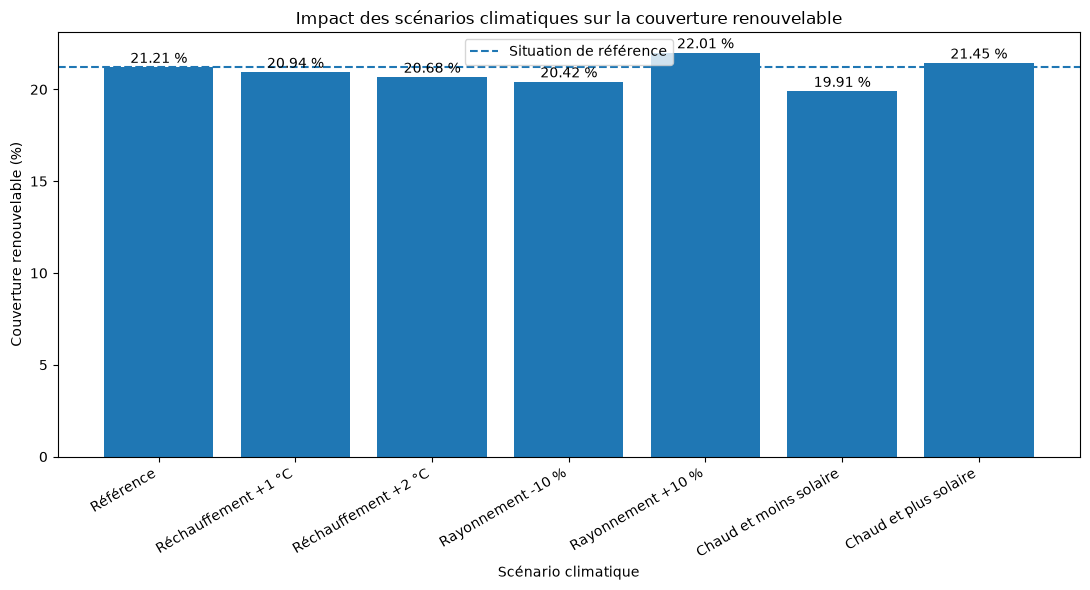

In [59]:
# Visualisation du taux de couverture renouvelable selon les scénarios

plt.figure(figsize=(11, 6))

bars = plt.bar(
    scenario_results["Scenario"],
    scenario_results["Coverage_pct"]
)

plt.axhline(
    reference["Coverage_pct"],
    linestyle="--",
    linewidth=1.5,
    label="Situation de référence"
)

plt.ylabel("Couverture renouvelable (%)")
plt.xlabel("Scénario climatique")
plt.title(
    "Impact des scénarios climatiques sur la couverture renouvelable"
)

plt.xticks(rotation=30, ha="right")
plt.legend()

for bar, value in zip(bars, scenario_results["Coverage_pct"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.05,
        f"{value:.2f} %",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

FIG_SCENARIO_COVERAGE = (
    FIGURES_DIR
    / "climate_scenarios_renewable_coverage.png"
)

plt.savefig(
    FIG_SCENARIO_COVERAGE,
    dpi=300,
    bbox_inches="tight"
)

print(
    "Figure enregistrée :",
    FIG_SCENARIO_COVERAGE
)

plt.show()

Figure enregistrée : c:\Users\celes\Desktop\PFE\figures\climate_scenarios_energy_deficit.png


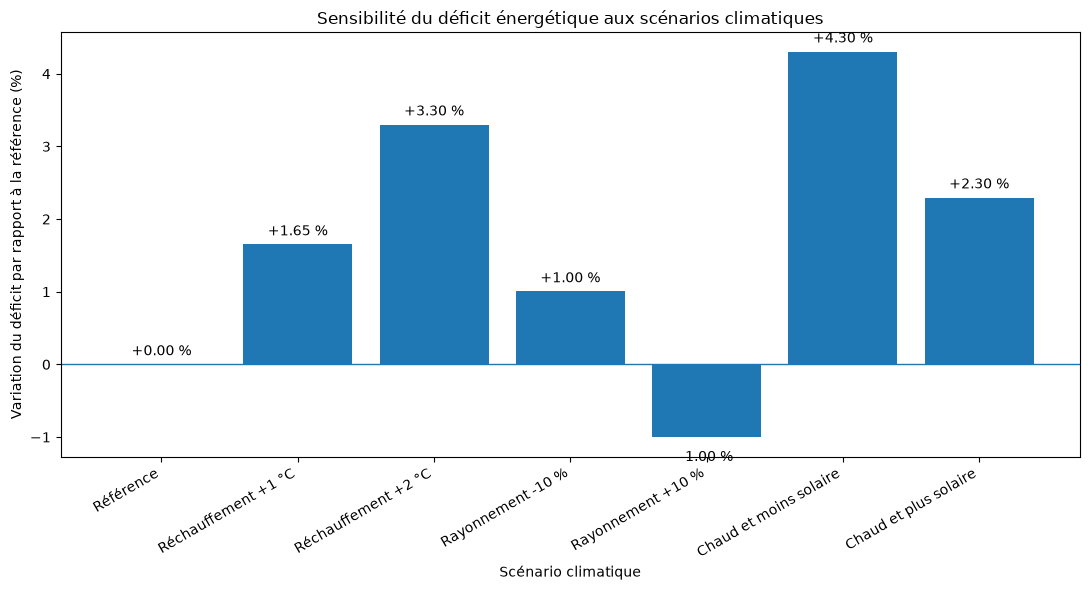

In [60]:
# Visualisation de la variation du déficit énergétique

plt.figure(figsize=(11, 6))

bars = plt.bar(
    scenario_comparison["Scenario"],
    scenario_comparison["Variation_deficit_pct"]
)

plt.axhline(
    0,
    linewidth=1
)

plt.ylabel("Variation du déficit par rapport à la référence (%)")
plt.xlabel("Scénario climatique")
plt.title(
    "Sensibilité du déficit énergétique aux scénarios climatiques"
)

plt.xticks(rotation=30, ha="right")

for bar, value in zip(
    bars,
    scenario_comparison["Variation_deficit_pct"]
):
    offset = 0.08 if value >= 0 else -0.18

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + offset,
        f"{value:+.2f} %",
        ha="center",
        va="bottom" if value >= 0 else "top"
    )

plt.tight_layout()

FIG_SCENARIO_DEFICIT = (
    FIGURES_DIR
    / "climate_scenarios_energy_deficit.png"
)

plt.savefig(
    FIG_SCENARIO_DEFICIT,
    dpi=300,
    bbox_inches="tight"
)

print(
    "Figure enregistrée :",
    FIG_SCENARIO_DEFICIT
)

plt.show()

### Lecture des scénarios climatiques

Les résultats montrent que l'évolution des conditions climatiques peut modifier
simultanément la disponibilité de la production renouvelable et les besoins
électriques.

Parmi les scénarios étudiés, la combinaison d'un réchauffement de +2 °C et
d'une diminution de 10 % du rayonnement solaire apparaît comme la situation
la plus défavorable. Le taux de couverture renouvelable passe de 21,21 % dans
la situation de référence à 19,91 %, tandis que le déficit énergétique augmente
de 4,30 %.

À l'inverse, une augmentation de 10 % du rayonnement solaire améliore la
production photovoltaïque et porte la couverture renouvelable à 22,01 %,
avec une réduction du déficit de 1 %.

Ces simulations constituent des scénarios de sensibilité et non des projections
climatiques futures. Elles permettent d'évaluer la réaction du système
énergétique à différentes modifications plausibles des variables climatiques
et d'identifier les situations dans lesquelles des mesures d'adaptation seraient
nécessaires.

## 36. Aide à la décision pour l'adaptation du système énergétique

L'analyse précédente a permis de quantifier la sensibilité de l'équilibre
énergétique à différentes modifications des conditions climatiques.

La prévision constitue cependant une étape intermédiaire : son intérêt
opérationnel réside dans sa capacité à anticiper les situations dans lesquelles
la production renouvelable devient insuffisante par rapport à la demande.

Cette section propose donc une couche simple d'aide à la décision. À partir
du taux de couverture renouvelable et du déficit estimé pour chaque scénario,
les situations énergétiques sont classées selon plusieurs niveaux de vigilance.

L'objectif n'est pas de simuler le fonctionnement détaillé d'un réseau
électrique ou d'un système de stockage, pour lesquels des données techniques
supplémentaires seraient nécessaires, mais de transformer les résultats
prédictifs en indicateurs directement exploitables pour l'aide à la décision.

In [61]:
# Classification des scénarios selon la dégradation de la couverture renouvelable par rapport à la référence

decision_results = scenario_comparison.copy()

def classify_energy_risk(variation_coverage):
    if variation_coverage >= 0:
        return "Situation favorable"
    elif variation_coverage >= -0.5:
        return "Vigilance"
    elif variation_coverage >= -1.0:
        return "Risque modéré"
    else:
        return "Risque élevé"


decision_results["Niveau_vigilance"] = (
    decision_results["Variation_coverage_points"]
    .apply(classify_energy_risk)
)

print("CLASSIFICATION DES SCÉNARIOS ÉNERGÉTIQUES")

decision_results[
    [
        "Scenario",
        "Coverage_pct",
        "Variation_coverage_points",
        "Variation_deficit_pct",
        "Niveau_vigilance"
    ]
].round(2)

CLASSIFICATION DES SCÉNARIOS ÉNERGÉTIQUES


,Scenario,Coverage_pct,Variation_coverage_points,Variation_deficit_pct,Niveau_vigilance
0,Référence,21.21,0.00,0.00,Situation favorable
1,Réchauffement +1 °C,20.94,-0.27,1.65,Vigilance
2,Réchauffement +2 °C,20.68,-0.54,3.30,Risque modéré
3,Rayonnement -10 %,20.42,-0.79,1.00,Risque modéré
4,Rayonnement +10 %,22.01,0.79,-1.00,Situation favorable
5,Chaud et moins solaire,19.91,-1.31,4.30,Risque élevé
6,Chaud et plus solaire,21.45,0.23,2.30,Situation favorable


### Définition des niveaux de vigilance

Les seuils utilisés dans cette classification ne correspondent pas à des
seuils réglementaires du secteur électrique. Ils sont définis dans le cadre
de cette étude afin de comparer les scénarios à une même situation de
référence.

Une variation positive ou nulle de la couverture est considérée comme
favorable. Une diminution inférieure à 0,5 point correspond à un niveau de
vigilance, une diminution comprise entre 0,5 et 1 point à un risque modéré,
et une diminution supérieure à 1 point à un risque élevé.

Cette classification fournit ainsi un indicateur synthétique de sensibilité
du système aux perturbations climatiques étudiées.

In [62]:
# Génération de recommandations d'aide à la décision

def recommend_action(risk_level):
    recommendations = {
        "Situation favorable":
            "Maintenir la stratégie actuelle et surveiller les prévisions.",

        "Vigilance":
            "Renforcer la surveillance de la demande et de la production renouvelable.",

        "Risque modéré":
            "Anticiper des moyens complémentaires de flexibilité ou d'approvisionnement.",

        "Risque élevé":
            "Préparer des mesures d'adaptation renforcées et sécuriser des ressources complémentaires."
    }

    return recommendations[risk_level]


decision_results["Recommandation"] = (
    decision_results["Niveau_vigilance"]
    .apply(recommend_action)
)

print("AIDE À LA DÉCISION ÉNERGÉTIQUE")

decision_results[
    [
        "Scenario",
        "Niveau_vigilance",
        "Recommandation"
    ]
]

AIDE À LA DÉCISION ÉNERGÉTIQUE


,Scenario,Niveau_vigilance,Recommandation
0,Référence,Situation favorable,Maintenir la stratégie actuelle et surveiller ...
1,Réchauffement +1 °C,Vigilance,Renforcer la surveillance de la demande et de ...
2,Réchauffement +2 °C,Risque modéré,Anticiper des moyens complémentaires de flexib...
3,Rayonnement -10 %,Risque modéré,Anticiper des moyens complémentaires de flexib...
4,Rayonnement +10 %,Situation favorable,Maintenir la stratégie actuelle et surveiller ...
5,Chaud et moins solaire,Risque élevé,Préparer des mesures d'adaptation renforcées e...
6,Chaud et plus solaire,Situation favorable,Maintenir la stratégie actuelle et surveiller ...


### Interprétation pour l'aide à la décision

La classification confirme que les conséquences énergétiques dépendent de
la combinaison des variations climatiques affectant la production et la
demande.

Le scénario « Chaud et moins solaire » est classé au niveau de risque le plus
élevé parmi les situations étudiées. L'augmentation de la température accroît
la demande électrique tandis que la diminution du rayonnement réduit
simultanément la production photovoltaïque. Cette combinaison conduit à la
plus forte dégradation de la couverture renouvelable.

À l'inverse, l'augmentation du rayonnement solaire améliore la contribution
photovoltaïque et peut partiellement compenser l'effet d'une hausse de la
température sur la demande.

Le système proposé permet ainsi de transformer les résultats issus de
l'analyse climatique et énergétique en niveaux de vigilance et en
recommandations simples. Il constitue une couche d'aide à la décision pouvant
être utilisée pour anticiper les situations défavorables et préparer des
mesures de flexibilité, d'approvisionnement ou d'adaptation des capacités
énergétiques.

## 37. Estimation de l'effort d'adaptation énergétique

L'identification d'un scénario défavorable ne suffit pas à elle seule pour
orienter une décision énergétique. Il est également utile d'estimer l'ampleur
de l'adaptation nécessaire pour compenser la dégradation induite par les
conditions climatiques considérées.

Dans cette section, la situation de référence est utilisée comme objectif de
couverture renouvelable. Pour chaque scénario climatique, on estime la
production renouvelable supplémentaire qui serait nécessaire pour retrouver
ce niveau de couverture, compte tenu de la demande électrique estimée.

Cette approche ne constitue pas un dimensionnement technique d'une nouvelle
installation photovoltaïque, éolienne ou d'un système de stockage. Elle fournit
un indicateur quantitatif du besoin d'adaptation énergétique associé à chaque
scénario.

In [63]:
# Estimation du besoin d'adaptation pour maintenir la couverture renouvelable de référence

adaptation_results = scenario_results.copy()

reference_coverage = adaptation_results.loc[
    adaptation_results["Scenario"] == "Référence",
    "Coverage_pct"
].iloc[0]

adaptation_results["Renewable_required"] = (
    adaptation_results["Demand_estimated"]
    * reference_coverage / 100
)

adaptation_results["Additional_renewable_needed"] = (
    adaptation_results["Renewable_required"]
    - adaptation_results["Renewable_estimated"]
).clip(lower=0)

adaptation_results["Additional_renewable_pct"] = (
    adaptation_results["Additional_renewable_needed"]
    / adaptation_results["Renewable_estimated"]
    * 100
)

print("BESOIN D'ADAPTATION ÉNERGÉTIQUE")

adaptation_results[
    [
        "Scenario",
        "Coverage_pct",
        "Renewable_estimated",
        "Renewable_required",
        "Additional_renewable_needed",
        "Additional_renewable_pct"
    ]
].round(2)

BESOIN D'ADAPTATION ÉNERGÉTIQUE


,Scenario,Coverage_pct,Renewable_estimated,Renewable_required,Additional_renewable_needed,Additional_renewable_pct
0,Référence,21.21,5510.18,5510.18,0.00,0.00
1,Réchauffement +1 °C,20.94,5510.18,5581.82,71.64,1.30
2,Réchauffement +2 °C,20.68,5510.18,5653.46,143.28,2.60
3,Rayonnement -10 %,20.42,5304.67,5510.18,205.51,3.87
4,Rayonnement +10 %,22.01,5715.69,5510.18,0.00,0.00
5,Chaud et moins solaire,19.91,5304.67,5653.46,348.79,6.58
6,Chaud et plus solaire,21.45,5715.69,5653.46,0.00,0.00


### Interprétation du besoin d'adaptation énergétique

Les résultats montrent que les scénarios climatiques défavorables peuvent
nécessiter une augmentation de la contribution renouvelable afin de maintenir
le niveau de couverture observé dans la situation de référence.

Une hausse de température de +1 °C nécessiterait, dans les conditions
simulées, environ 1,30 % de production renouvelable supplémentaire pour
compenser l'augmentation estimée de la demande. Pour un réchauffement de
+2 °C, cet effort atteindrait environ 2,60 %.

Une diminution de 10 % du rayonnement solaire produit un besoin d'adaptation
plus important, estimé à environ 3,87 % de production renouvelable
supplémentaire.

Le scénario combiné « Chaud et moins solaire » constitue la situation la plus
défavorable parmi celles étudiées. Il nécessiterait environ 6,58 % de
production renouvelable supplémentaire pour retrouver le taux de couverture
de référence de 21,21 %.

À l'inverse, les scénarios caractérisés par une augmentation du rayonnement
solaire atteignent déjà un taux de couverture supérieur à la référence et ne
présentent donc pas, selon cet indicateur, de besoin de production
renouvelable supplémentaire.

Ces estimations ne constituent pas un dimensionnement d'infrastructures.
Elles quantifient plutôt l'effort d'adaptation énergétique qui pourrait être
compensé par différentes solutions : augmentation des capacités
renouvelables, stockage, flexibilité de la demande ou moyens complémentaires
d'approvisionnement.

### Principe de l'indicateur d'adaptation

Le besoin d'adaptation correspond à l'écart entre la production renouvelable
estimée dans un scénario climatique et la production qui serait nécessaire
pour maintenir le taux de couverture observé dans la situation de référence.

Lorsque cet écart est nul, le scénario ne nécessite pas de production
renouvelable supplémentaire pour maintenir la couverture de référence.

Lorsqu'il est positif, il représente un besoin théorique de production
renouvelable complémentaire. Celui-ci pourrait, dans une application
opérationnelle, être satisfait par différentes stratégies telles que
l'augmentation des capacités renouvelables, le stockage, la flexibilité de
la demande ou des moyens complémentaires d'approvisionnement.

Le calcul présenté ici constitue donc un indicateur d'aide à la décision et
non un dimensionnement technique des infrastructures énergétiques.

Figure enregistrée : c:\Users\celes\Desktop\PFE\figures\climate_energy_adaptation_effort.png


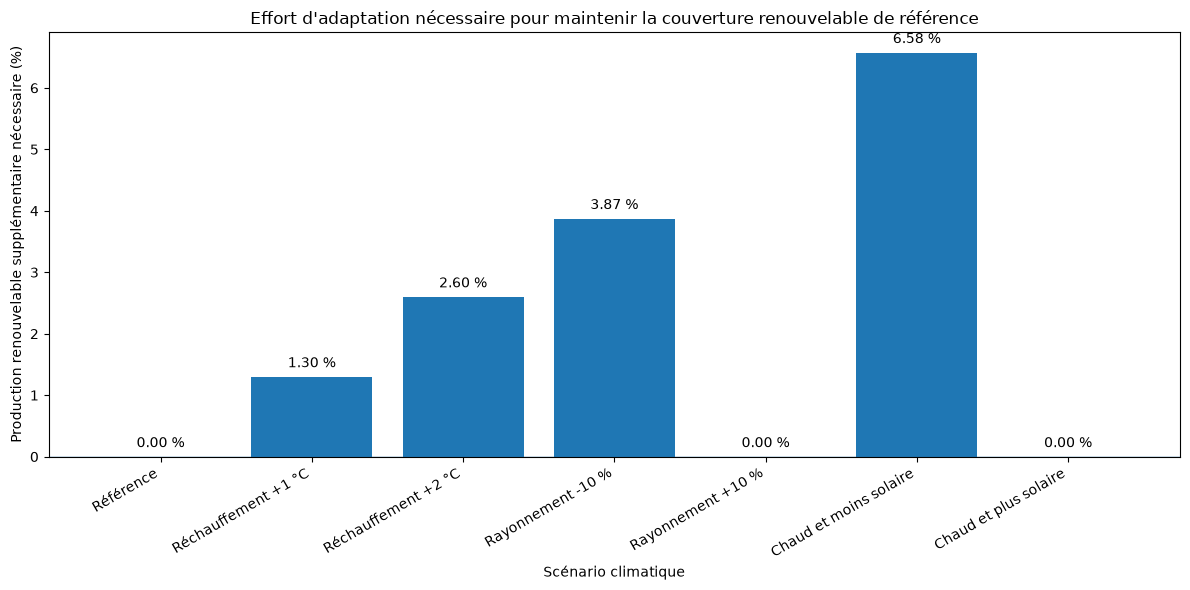

In [64]:
# Visualisation du besoin de production renouvelable supplémentaire

adaptation_plot = adaptation_results.copy()

plt.figure(figsize=(12, 6))

bars = plt.bar(
    adaptation_plot["Scenario"],
    adaptation_plot["Additional_renewable_pct"]
)

plt.axhline(
    y=0,
    linewidth=1
)

plt.ylabel("Production renouvelable supplémentaire nécessaire (%)")
plt.xlabel("Scénario climatique")
plt.title(
    "Effort d'adaptation nécessaire pour maintenir la couverture renouvelable de référence"
)

plt.xticks(rotation=30, ha="right")

for bar, value in zip(
    bars,
    adaptation_plot["Additional_renewable_pct"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.1,
        f"{value:.2f} %",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

FIG_ADAPTATION_EFFORT = (
    FIGURES_DIR
    / "climate_energy_adaptation_effort.png"
)

plt.savefig(
    FIG_ADAPTATION_EFFORT,
    dpi=300,
    bbox_inches="tight"
)

print(
    "Figure enregistrée :",
    FIG_ADAPTATION_EFFORT
)

plt.show()

### Lecture de l'effort d'adaptation

La quantification du besoin d'adaptation met en évidence une forte dépendance
de l'équilibre énergétique aux conditions climatiques considérées.

Les scénarios de réchauffement augmentent progressivement l'effort nécessaire
pour maintenir le taux de couverture renouvelable de référence : celui-ci
passe de 1,30 % pour une hausse de température de +1 °C à 2,60 % pour une
hausse de +2 °C.

Une diminution de 10 % du rayonnement solaire conduit à un besoin plus
important, estimé à 3,87 %, en raison de la réduction de la production
photovoltaïque.

Le scénario combiné « Chaud et moins solaire » apparaît comme le plus
contraignant, avec un besoin estimé à 6,58 % de production renouvelable
supplémentaire. Il illustre l'effet cumulé d'une hausse de la demande liée à
la température et d'une diminution de la production photovoltaïque.

Ces résultats montrent l'intérêt d'intégrer l'information climatique dans
la planification énergétique : l'anticipation de conditions défavorables
permet d'estimer en amont l'effort d'adaptation nécessaire pour préserver
un niveau donné de couverture renouvelable.

## 38. Synthèse des principaux résultats

Le notebook a étudié le problème énergétique selon deux échelles temporelles
complémentaires.

À long terme, l'analyse des données NASA POWER sur la période 1990–2025 a
permis d'identifier plusieurs évolutions climatiques locales. La température
présente la tendance la plus marquée, avec une augmentation estimée à environ
0,49 °C par décennie. Une évolution positive plus modérée du rayonnement
solaire a également été observée, tandis que les tendances relatives au vent
et à l'humidité se sont révélées moins robustes statistiquement.

À court terme, les prévisions de production photovoltaïque, de production
éolienne et de demande électrique ont été combinées afin d'estimer le bilan
énergétique et le taux de couverture renouvelable à l'horizon H+1.

Le taux de couverture prévisionnel présente une MAE d'environ 1,43 point de
pourcentage et un coefficient de détermination de 0,9854. La transformation
de cet indicateur en niveaux de couverture permet d'obtenir une concordance
de 92,34 % avec les niveaux réellement observés.

L'analyse climat-énergie menée sur la période commune de 164 jours met
notamment en évidence une forte association entre rayonnement solaire et
production photovoltaïque ainsi qu'entre température et demande électrique.

Enfin, les scénarios de sensibilité montrent que la combinaison d'une
température plus élevée et d'un rayonnement solaire plus faible constitue le
cas le plus défavorable parmi les situations étudiées. Dans le scénario
« Chaud et moins solaire », le taux de couverture renouvelable passe de
21,21 % à 19,91 %, le déficit augmente de 4,30 % et l'effort théorique
d'adaptation nécessaire pour retrouver la couverture de référence atteint
environ 6,58 % de production renouvelable supplémentaire.

In [65]:
# Synthèse des résultats principaux du notebook

summary_results = pd.DataFrame([
    {
        "Dimension": "Climat long terme",
        "Indicateur": "Tendance température",
        "Résultat": "+0,486 °C / décennie"
    },
    {
        "Dimension": "Climat long terme",
        "Indicateur": "Tendance rayonnement solaire",
        "Résultat": "+0,045 kWh/m²/jour / décennie"
    },
    {
        "Dimension": "Prévision énergétique",
        "Indicateur": "R² bilan énergétique",
        "Résultat": f"{balance_r2:.4f}"
    },
    {
        "Dimension": "Prévision énergétique",
        "Indicateur": "MAE taux de couverture",
        "Résultat": f"{coverage_mae:.2f} points"
    },
    {
        "Dimension": "Aide à la décision",
        "Indicateur": "Concordance niveaux de couverture",
        "Résultat": f"{coverage_level_accuracy:.2f} %"
    },
    {
        "Dimension": "Climat-énergie",
        "Indicateur": "Corrélation rayonnement / PV",
        "Résultat": "Pearson r = 0,7415"
    },
    {
        "Dimension": "Climat-énergie",
        "Indicateur": "Corrélation température / demande",
        "Résultat": "Pearson r = 0,7080"
    },
    {
        "Dimension": "Adaptation climatique",
        "Indicateur": "Scénario le plus défavorable",
        "Résultat": "Chaud et moins solaire"
    },
    {
        "Dimension": "Adaptation climatique",
        "Indicateur": "Besoin supplémentaire maximal",
        "Résultat": "6,58 %"
    }
])

print("SYNTHÈSE DES PRINCIPAUX RÉSULTATS")

display(summary_results)

SYNTHÈSE DES PRINCIPAUX RÉSULTATS


,Dimension,Indicateur,Résultat
0,Climat long terme,Tendance température,"+0,486 °C / décennie"
1,Climat long terme,Tendance rayonnement solaire,"+0,045 kWh/m²/jour / décennie"
2,Prévision énergétique,R² bilan énergétique,0.9901
3,Prévision énergétique,MAE taux de couverture,1.43 points
4,Aide à la décision,Concordance niveaux de couverture,92.34 %
5,Climat-énergie,Corrélation rayonnement / PV,"Pearson r = 0,7415"
6,Climat-énergie,Corrélation température / demande,"Pearson r = 0,7080"
7,Adaptation climatique,Scénario le plus défavorable,Chaud et moins solaire
8,Adaptation climatique,Besoin supplémentaire maximal,"6,58 %"


In [66]:
# Enregistrement des résultats finaux

summary_results.to_csv(
    RESULTS_DIR / "climate_energy_summary.csv",
    index=False
)

scenario_results.to_csv(
    RESULTS_DIR / "climate_energy_scenarios.csv",
    index=False
)

decision_results.to_csv(
    RESULTS_DIR / "climate_energy_decision_support.csv",
    index=False
)

adaptation_results.to_csv(
    RESULTS_DIR / "climate_energy_adaptation.csv",
    index=False
)

print("RÉSULTATS DU NOTEBOOK ENREGISTRÉS DANS LE DOSSIER results/")

RÉSULTATS DU NOTEBOOK ENREGISTRÉS DANS LE DOSSIER results/


## 39. Limites de l'étude

Plusieurs limites doivent être prises en compte dans l'interprétation des
résultats.



### Données climatiques

Les données NASA POWER utilisées pour l'analyse de long terme concernent la
région de Fès. Les tendances observées sont donc locales et ne peuvent pas être
généralisées automatiquement à l'ensemble du Maroc.

L'analyse 1990-2025 met en évidence des tendances historiques, mais elle ne
constitue pas une attribution causale au changement climatique anthropique.

### Période commune climat-énergie

L'analyse directe des relations entre climat et énergie repose sur une période
commune limitée à 164 jours, du 21 juillet au 31 décembre 2021.

Les corrélations observées peuvent donc être influencées par la saisonnalité et
ne représentent pas nécessairement l'ensemble des comportements possibles sur
une année complète ou plusieurs années.

### Production éolienne

La vitesse du vent disponible dans NASA POWER est mesurée ou estimée à 10 m,
alors que les turbines éoliennes fonctionnent à des hauteurs nettement
supérieures.

La faible relation observée entre cette variable et la production éolienne
limite donc fortement l'interprétation des scénarios associés au vent.

### Scénarios climatiques

Les scénarios de variation de température et de rayonnement sont des scénarios
de sensibilité expérimentaux.

Ils ne correspondent pas à des projections climatiques issues de modèles
CMIP ou de scénarios SSP du GIEC et ne doivent pas être interprétés comme des
prévisions du climat futur.

### Aide à la décision

Les niveaux de vigilance et recommandations proposés constituent un prototype
d'aide à la décision.

Le projet ne dispose pas de données détaillées sur les capacités de stockage,
les moyens pilotables, les coûts, les importations, les contraintes du réseau
ou les capacités installées. Il ne réalise donc pas une optimisation complète
du système électrique.

Ces limites définissent également plusieurs perspectives d'amélioration du
travail.

## Conclusion

Ce notebook complète la prévision énergétique à court terme développée dans
les étapes précédentes du projet par une analyse climatique de long terme et
une couche d'aide à la décision.

L'étude des données NASA POWER sur la période 1990-2025 met en évidence une
évolution significative de certaines conditions climatiques locales,
particulièrement de la température.

L'analyse réalisée sur la période commune climat-énergie montre ensuite que
certaines de ces variables sont fortement associées au comportement du système
énergétique. Le rayonnement solaire est notamment lié à la production
photovoltaïque, tandis que la température présente une association importante
avec la demande électrique.

Les prévisions produites par les modèles d'intelligence artificielle ont été
combinées afin d'anticiper l'équilibre entre production renouvelable et
demande à l'horizon H+1. Cette information a ensuite été transformée en
niveaux de couverture et en indicateurs d'aide à la décision.

Enfin, les scénarios de sensibilité climatique ont permis d'estimer les
conséquences potentielles de différentes modifications des conditions
climatiques sur l'équilibre énergétique. Le scénario associant une hausse de
température à une diminution du rayonnement solaire apparaît comme le plus
contraignant parmi les situations étudiées et nécessite le plus important
effort d'adaptation pour maintenir le niveau de couverture renouvelable de
référence.

Le projet articule ainsi deux horizons complémentaires :

**à court terme**, l'intelligence artificielle permet d'anticiper la production
photovoltaïque, la production éolienne et la demande électrique afin de mieux
préparer les décisions opérationnelles ;

**à plus long terme**, l'analyse de l'évolution climatique permet d'identifier
des changements susceptibles de modifier les conditions de production et de
consommation et d'estimer les besoins d'adaptation associés.

Cette combinaison permet de replacer la prévision énergétique dans une logique
plus large d'anticipation et d'adaptation du système énergétique face à
l'évolution des conditions climatiques.